# Instrução do Projeto

A Film Junky Union, uma nova comunidade para entusiastas de filmes clássicos, está desenvolvendo um sistema para filtrar e categorizar resenhas de filmes. O objetivo é treinar um modelo para detectar automaticamente resenhas negativas. Você usará um conjunto de dados de resenhas de filmes do IMDB com rotulagem de polaridade para criar um modelo para classificar resenhas como positivas e negativas. Ele precisará ter um valor F1 de pelo menos 0,85.

## Validação de configuração do ambiente

In [ ]:
import sys
import torch
import pandas as pd
import numpy as np
import sklearn
import nltk
import spacy
import transformers
import lightgbm
import matplotlib
import seaborn

print("=== AMBIENTE ===")
print("Python:", sys.version)
print("Executável:", sys.executable)

print("\n=== BIBLIOTECAS ===")
print("PyTorch:", torch.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("NLTK:", nltk.__version__)
print("spaCy:", spacy.__version__)
print("Transformers:", transformers.__version__)
print("LightGBM:", lightgbm.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", seaborn.__version__)

print("\n=== PROCESSAMENTO ===")
print("CUDA disponível:", torch.cuda.is_available())
print("Dispositivo:", "CUDA" if torch.cuda.is_available() else "CPU")

print("\n=== MODELO SPACY ===")
nlp = spacy.load("en_core_web_sm")
doc = nlp("This movie was surprisingly good.")

print([(token.text, token.lemma_, token.pos_) for token in doc])

print("\n=== RECURSOS NLTK ===")
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

print("Stopwords:", len(stopwords.words("english")))
print("Tokenização:", word_tokenize("This movie was surprisingly good."))

print("\nAmbiente validado!")

=== AMBIENTE ===
Python: 3.9.23 (main, Jun  5 2025, 13:25:08) [MSC v.1929 64 bit (AMD64)]
Executável: e:\DataScience\anaconda3\envs\tripleten-p14\python.exe

=== BIBLIOTECAS ===
PyTorch: 1.10.0
Pandas: 1.2.4
NumPy: 1.21.2
Scikit-learn: 0.24.1
NLTK: 3.6.1
spaCy: 3.2.0
Transformers: 4.12.5
LightGBM: 3.3.1
Matplotlib: 3.3.4
Seaborn: 0.11.1

=== PROCESSAMENTO ===
CUDA disponível: False
Dispositivo: CPU

=== MODELO SPACY ===
[('This', 'this', 'DET'), ('movie', 'movie', 'NOUN'), ('was', 'be', 'AUX'), ('surprisingly', 'surprisingly', 'ADV'), ('good', 'good', 'ADJ'), ('.', '.', 'PUNCT')]

=== RECURSOS NLTK ===
Stopwords: 198
Tokenização: ['This', 'movie', 'was', 'surprisingly', 'good', '.']

Ambiente validado!


In [33]:
import ipywidgets as widgets
from IPython.display import display

print("ipywidgets:", widgets.__version__)

display(widgets.IntSlider(
    value=5,
    min=0,
    max=10,
    description="Teste:"
))

ipywidgets: 8.1.5


IntSlider(value=5, description='Teste:', max=10)

In [34]:
from tqdm.auto import tqdm
import time

for i in tqdm(range(10), desc="Teste de progresso"):
    time.sleep(0.1)

Teste de progresso:   0%|          | 0/10 [00:00<?, ?it/s]

## Inicialização

In [35]:
import math

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from tqdm.auto import tqdm

In [36]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'
# a próxima linha fornece gráficos de melhor qualidade em telas HiDPI
%config InlineBackend.figure_format = 'retina'

plt.style.use('seaborn')

In [37]:
# isso é para usar progress_apply, leia mais em https://pypi.org/project/tqdm/#pandas-integration
tqdm.pandas()

In [55]:
# Definindo uma constante de semente aleatória para reprodutibilidade
RANDOM_STATE = 12345

## Carregar Dados

In [38]:
try:
    df_reviews = pd.read_csv(
        '/datasets/imdb_reviews.tsv',
        sep='\t',
        dtype={'votes': 'Int64'}
    )
    print("Dataset carregado do ambiente TripleTen.")

except FileNotFoundError:
    df_reviews = pd.read_csv(
        'datasets/imdb_reviews.tsv',
        sep='\t',
        dtype={'votes': 'Int64'}
    )
    print("Dataset carregado do ambiente local.")

print("Dimensões do dataset:", df_reviews.shape)

Dataset carregado do ambiente local.
Dimensões do dataset: (47331, 17)


In [39]:
# verificando os dados
print("Informações do dataset:")
display(df_reviews.info())
print()
print("Primeiras linhas do dataset:")
display(df_reviews.head())
print()
print('Dados descritivos do dataset:')
display(df_reviews.describe())


Informações do dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47331 entries, 0 to 47330
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   tconst           47331 non-null  object 
 1   title_type       47331 non-null  object 
 2   primary_title    47331 non-null  object 
 3   original_title   47331 non-null  object 
 4   start_year       47331 non-null  int64  
 5   end_year         47331 non-null  object 
 6   runtime_minutes  47331 non-null  object 
 7   is_adult         47331 non-null  int64  
 8   genres           47331 non-null  object 
 9   average_rating   47329 non-null  float64
 10  votes            47329 non-null  Int64  
 11  review           47331 non-null  object 
 12  rating           47331 non-null  int64  
 13  sp               47331 non-null  object 
 14  pos              47331 non-null  int64  
 15  ds_part          47331 non-null  object 
 16  idx              47331 non-null  i

None


Primeiras linhas do dataset:


,tconst,title_type,primary_title,original_title,start_year,end_year,runtime_minutes,is_adult,genres,average_rating,votes,review,rating,sp,pos,ds_part,idx
0,tt0068152,movie,$,$,1971,\N,121,0,"Comedy,Crime,Drama",6.3,2218,The pakage implies that Warren Beatty and Gold...,1,neg,0,train,8335
1,tt0068152,movie,$,$,1971,\N,121,0,"Comedy,Crime,Drama",6.3,2218,How the hell did they get this made?! Presenti...,1,neg,0,train,8336
2,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,There is no real story the film seems more lik...,3,neg,0,test,2489
3,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,Um .... a serious film about troubled teens in...,7,pos,1,test,9280
4,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,I'm totally agree with GarryJohal from Singapo...,9,pos,1,test,9281



Dados descritivos do dataset:


,start_year,is_adult,average_rating,votes,rating,pos,idx
count,47331.000000,47331.000000,47329.000000,4.732900e+04,47331.000000,47331.000000,47331.000000
mean,1989.631235,0.001732,5.998278,2.556292e+04,5.484608,0.498954,6279.697999
std,19.600364,0.041587,1.494289,8.367004e+04,3.473109,0.500004,3605.702545
min,1894.000000,0.000000,1.400000,9.000000e+00,1.000000,0.000000,0.000000
25%,1982.000000,0.000000,5.100000,8.270000e+02,2.000000,0.000000,3162.000000
50%,1998.000000,0.000000,6.300000,3.197000e+03,4.000000,0.000000,6299.000000
75%,2004.000000,0.000000,7.100000,1.397400e+04,9.000000,1.000000,9412.000000
max,2010.000000,1.000000,9.700000,1.739448e+06,10.000000,1.000000,12499.000000


In [40]:
# Contagem de valores por partição (treino e teste)
display(df_reviews['ds_part'].value_counts())

train    23796
test     23535
Name: ds_part, dtype: int64

## Preparação dos dados - Tratamento de nulos e duplicatas

In [41]:
# Checando valores nulos
print("Valores nulos por coluna:")
display(df_reviews.isnull().sum())

# Checando valores duplicados absolutos
print("Valores duplicados:", df_reviews.duplicated().sum())

Valores nulos por coluna:


tconst             0
title_type         0
primary_title      0
original_title     0
start_year         0
end_year           0
runtime_minutes    0
is_adult           0
genres             0
average_rating     2
votes              2
review             0
rating             0
sp                 0
pos                0
ds_part            0
idx                0
dtype: int64

Valores duplicados: 0


In [42]:
# Checando valores duplicados entre as partições ds_part (conjunto de treino e de teste) do dataset
duplicates = df_reviews.drop(columns='ds_part').duplicated()

print("Total de duplicatas desconsiderando ds_part:", duplicates.sum())

# Visualizando as linhas duplicadas, se houver
if duplicates.any():
    duplicate_rows = df_reviews[df_reviews.drop(columns='ds_part').duplicated(keep=False)].sort_values('review')

    print("\nLinhas duplicadas:")
    display(duplicate_rows)

    # Separando as partições de treino e teste para verificar se há duplicatas entre elas
    train_reviews = df_reviews[ df_reviews['ds_part'] == 'train'].drop(columns='ds_part')
    test_reviews = df_reviews[df_reviews['ds_part'] == 'test'].drop(columns='ds_part')

    duplicates_between_partitions = train_reviews.merge(test_reviews, how='inner')

    if not duplicates_between_partitions.empty:
        print("\nLinhas duplicadas entre treino e teste:")
        display(duplicates_between_partitions)
    else:
        print("\nNão há linhas duplicadas entre treino e teste.")
else:
    print("\nNão há linhas duplicadas no dataset.")

Total de duplicatas desconsiderando ds_part: 0

Não há linhas duplicadas no dataset.


In [43]:
## Checando duplicatas apenas no subset de colunas que são relevantes para o projeto (review, pos, ds_part)
# Definindo as colunas relevantes para a análise
selected_columns = ['review', 'pos', 'ds_part']
df_subset = df_reviews[selected_columns]

# Checando valores duplicados entre as partições
duplicates = df_subset.duplicated()

print("Total de duplicatas no subset:", duplicates.sum())

# Visualizando as linhas duplicadas, se houver
if duplicates.any():

    duplicate_rows = df_subset[df_subset.duplicated(keep=False)].sort_values(['review', 'ds_part'])

    print("\nLinhas duplicadas:")
    display(duplicate_rows)

    # Separando as partições de treino e teste
    train_reviews = df_subset[df_subset['ds_part'] == 'train'].drop(columns='ds_part')
    test_reviews = df_subset[df_subset['ds_part'] == 'test'].drop(columns='ds_part')

    # Verificando duplicatas entre treino e teste
    duplicates_between_partitions = train_reviews.merge(test_reviews, how='inner')

    if not duplicates_between_partitions.empty:
        print("\nLinhas duplicadas entre treino e teste:")
        display(duplicates_between_partitions)
    else:
        print("\nNão há linhas duplicadas entre treino e teste.")

else:
    print("\nNão há duplicatas no subset selecionado.")

Total de duplicatas no subset: 90

Linhas duplicadas:


,review,pos,ds_part
33040,"Back in his youth, the old man had wanted to ...",0,train
33041,"Back in his youth, the old man had wanted to ...",0,train
36174,"First of all, I reviewed this documentary bec...",1,test
36175,"First of all, I reviewed this documentary bec...",1,test
36803,A friend and I went to see this movie. We have...,0,test
...,...,...,...
42051,"in this movie, joe pesci slams dunks a basketb...",0,train
19312,it's amazing that so many people that i know h...,1,train
19315,it's amazing that so many people that i know h...,1,train
13768,"when I first heard about this movie, I noticed...",1,test



Linhas duplicadas entre treino e teste:


,review,pos
0,"There has been a political documentary, of rec...",1


In [44]:
# Checando os dados compleots das linhas duplicadas identificadas
duplicate_rows_full = df_reviews.merge(
    duplicate_rows.drop_duplicates(), # removendo as duplicatas para evitar múltiplas junções
    on=['review', 'pos', 'ds_part'],
    how='inner'
)

display(duplicate_rows_full)

,tconst,title_type,primary_title,original_title,start_year,end_year,runtime_minutes,is_adult,genres,average_rating,votes,review,rating,sp,pos,ds_part,idx
0,tt0081949,tvMiniSeries,A Town Like Alice,A Town Like Alice,1981,1981,301,0,"Drama,Romance,War",8.3,849,I have seen this film at least 100 times and I...,10,pos,1,test,9765
1,tt0081949,tvMiniSeries,A Town Like Alice,A Town Like Alice,1981,1981,301,0,"Drama,Romance,War",8.3,849,I have seen this film at least 100 times and I...,10,pos,1,test,9768
2,tt0098994,movie,"After Dark, My Sweet","After Dark, My Sweet",1990,\N,114,0,"Crime,Drama,Mystery",6.6,3098,THE JIST: See something else. This film was hi...,7,pos,1,train,7728
3,tt0098994,movie,"After Dark, My Sweet","After Dark, My Sweet",1990,\N,114,0,"Crime,Drama,Mystery",6.6,3098,THE JIST: See something else. This film was hi...,7,pos,1,train,7729
4,tt0086662,tvSeries,Airwolf,Airwolf,1984,1986,60,0,"Action,Adventure,Sci-Fi",6.7,9592,I used to watch this show when I was a little ...,9,pos,1,train,6769
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
166,tt0463392,movie,Zombie Nation,Zombie Nation,2004,\N,81,0,Horror,2.0,7850,German filmmaker Ulli Lommel has managed a tas...,1,neg,0,train,10089
167,tt0463392,movie,Zombie Nation,Zombie Nation,2004,\N,81,0,Horror,2.0,7850,German filmmaker Ulli Lommel has managed a tas...,1,neg,0,train,10108
168,tt0972534,tvSeries,iCarly,iCarly,2007,2012,30,0,"Comedy,Family,Romance",6.6,31143,Nickelodeon has gone down the toilet. They hav...,1,neg,0,test,5652
169,tt0972534,tvSeries,iCarly,iCarly,2007,2012,30,0,"Comedy,Family,Romance",6.6,31143,Nickelodeon has gone down the toilet. They hav...,1,neg,0,test,5655


As duplicatas parecem ser reviews identicas separadas por `idx` diferentes. Como usaremos apenas `review`, para gerar as features, `pos` como target e `ds_part` para divisão dos dados, vamos remover essa duplicatas. 

Além disso, encontramos uma duplicata entre treino e teste. Vamo remover a ocorrência duplicada do conjunto de treino que já é ligeiramente maior. 

In [71]:
# Removendo duplicatas do dataset original, mantendo apenas a primeira ocorrência
print("Dimensões do dataset antes remoção de duplicatas:", df_reviews.shape)
df_reviews_clean = df_reviews.drop_duplicates(subset=['review', 'pos', 'ds_part'], keep='first').reset_index(drop=True).copy()
print("Dimensões do dataset após remoção de duplicatas:", df_reviews_clean.shape)

# Verificando se as duplicatas foram removidas
selected_columns = ['review', 'pos', 'ds_part']
df_subset = df_reviews_clean[selected_columns]

# Checando valores duplicados entre as partições
duplicates = df_subset.duplicated()

print("Duplicatas dentro das partições:", duplicates.sum())

# Verificar duplicatas entre treino e teste
train_reviews = df_subset[df_subset['ds_part'] == 'train'][['review', 'pos']]
test_reviews = df_subset[df_subset['ds_part'] == 'test'][['review', 'pos']]

duplicates_between_partitions = train_reviews.merge(test_reviews.drop_duplicates(),on=['review', 'pos'],how='inner')

print("Avaliações distintas compartilhadas entre treino e teste:",len(duplicates_between_partitions))

display(duplicates_between_partitions)

Dimensões do dataset antes remoção de duplicatas: (47331, 17)
Dimensões do dataset após remoção de duplicatas: (47241, 17)
Duplicatas dentro das partições: 0
Avaliações distintas compartilhadas entre treino e teste: 1


,review,pos
0,"There has been a political documentary, of rec...",1


In [72]:
# Separando o df original em treino e teste, com todas as colunas
train_reviews = df_reviews_clean[df_reviews_clean['ds_part'] == 'train']
test_reviews = df_reviews_clean[df_reviews_clean['ds_part'] == 'test']

# Removação do registro duplicado entre treino e teste, mantendo a ocorrência no conjunto de teste e removendo do conjunto de treino
train_reviews_clean = train_reviews.merge(
    duplicates_between_partitions, 
    on=['review', 'pos'], 
    how='left', # Juntando apenas as linhas que não estão presentes no conjunto de teste
    indicator=True # Registrando a origem de cada linha (se está apenas no conjunto de treino ou se também está no conjunto de teste)
    ).query("_merge == 'left_only'").drop(columns='_merge') # Filtrando apenas as linhas que estão apenas no conjunto de treino e removendo a coluna de indicador

# Criando uma cópia do conjunto de teste para clareza
test_reviews_clean = test_reviews.copy()

# Verificando o resultado
print("Registros removidos do treino:", len(train_reviews) - len(train_reviews_clean))

print("Registros preservados no teste:", len(test_reviews_clean))

Registros removidos do treino: 1
Registros preservados no teste: 23483


In [73]:
# Exibindo as primeiras linhas dos conjuntos de treino e teste limpos
print("Primeiras linhas do conjunto de teste limpo:")
display(test_reviews_clean.head())
print("Primeiras linhas do conjunto de treino limpo:")
display(train_reviews_clean.head())

# Juntando os conjuntos de treino e teste limpos em um único DataFrame
df_reviews_clean = pd.concat([train_reviews_clean, test_reviews_clean], ignore_index=True)
display(df_reviews_clean.sample(5, random_state=RANDOM_STATE))

Primeiras linhas do conjunto de teste limpo:


,tconst,title_type,primary_title,original_title,start_year,end_year,runtime_minutes,is_adult,genres,average_rating,votes,review,rating,sp,pos,ds_part,idx
2,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,There is no real story the film seems more lik...,3,neg,0,test,2489
3,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,Um .... a serious film about troubled teens in...,7,pos,1,test,9280
4,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,I'm totally agree with GarryJohal from Singapo...,9,pos,1,test,9281
5,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,This is the first movie I've seen from Singapo...,9,pos,1,test,9282
6,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,Yes non-Singaporean's can't see what's the big...,9,pos,1,test,9283


Primeiras linhas do conjunto de treino limpo:


,tconst,title_type,primary_title,original_title,start_year,end_year,runtime_minutes,is_adult,genres,average_rating,votes,review,rating,sp,pos,ds_part,idx
0,tt0068152,movie,$,$,1971,\N,121,0,"Comedy,Crime,Drama",6.3,2218,The pakage implies that Warren Beatty and Gold...,1,neg,0,train,8335
1,tt0068152,movie,$,$,1971,\N,121,0,"Comedy,Crime,Drama",6.3,2218,How the hell did they get this made?! Presenti...,1,neg,0,train,8336
2,tt0035958,movie,'Gung Ho!': The Story of Carlson's Makin Islan...,'Gung Ho!': The Story of Carlson's Makin Islan...,1943,\N,88,0,"Drama,History,War",6.1,1240,This true story of Carlson's Raiders is more o...,2,neg,0,train,9903
3,tt0035958,movie,'Gung Ho!': The Story of Carlson's Makin Islan...,'Gung Ho!': The Story of Carlson's Makin Islan...,1943,\N,88,0,"Drama,History,War",6.1,1240,Should have been titled 'Balderdash!' Little i...,2,neg,0,train,9905
4,tt0035958,movie,'Gung Ho!': The Story of Carlson's Makin Islan...,'Gung Ho!': The Story of Carlson's Makin Islan...,1943,\N,88,0,"Drama,History,War",6.1,1240,The movie 'Gung Ho!': The Story of Carlson's M...,4,neg,0,train,9904


,tconst,title_type,primary_title,original_title,start_year,end_year,runtime_minutes,is_adult,genres,average_rating,votes,review,rating,sp,pos,ds_part,idx
20216,tt0499540,movie,The Other,El otro,2007,\N,83,0,Drama,5.9,497,"I just came back from ""El Otro"" playing here i...",3,neg,0,train,8350
7438,tt0187078,movie,Gone in 60 Seconds,Gone in Sixty Seconds,2000,\N,118,0,"Action,Crime,Thriller",6.5,255457,The movie was a big Car Commercial. :-) But wh...,8,pos,1,train,6270
17298,tt0090713,movie,The Best of Times,The Best of Times,1986,\N,104,0,"Comedy,Drama,Sport",6.0,6422,Spoiler This movie is about such a concept. Wi...,7,pos,1,train,11758
21506,tt0450345,movie,The Wicker Man,The Wicker Man,2006,\N,102,0,"Horror,Mystery,Thriller",3.7,63008,"Prior to this release, Neil LaBute had this to...",1,neg,0,train,7566
6351,tt0457572,movie,Fido,Fido,2006,\N,93,0,"Comedy,Drama,Horror",6.7,27763,"Due to the invention of a ""The Domestication C...",7,pos,1,train,8236


In [74]:
# Checagem final de duplicatas no dataset limpo
print("Dataset original:", df_reviews.shape)
print("Dataset após limpeza:", df_reviews_clean.shape)

print("Duplicatas restantes dentro das partições:",
      df_reviews_clean.duplicated(
          subset=['review', 'pos', 'ds_part']
      ).sum())

print("Sobreposições restantes entre treino e teste:",
      len(
          train_reviews_clean[['review', 'pos']].merge(
              test_reviews[['review', 'pos']],
              on=['review', 'pos'],
              how='inner'
          )
      ))

Dataset original: (47331, 17)
Dataset após limpeza: (47240, 17)
Duplicatas restantes dentro das partições: 0
Sobreposições restantes entre treino e teste: 0


In [75]:
# Verificando valores ausentes no dataset limpo
print("Valores ausentes após a limpeza:")
display(df_reviews_clean.isnull().sum())

Valores ausentes após a limpeza:


tconst             0
title_type         0
primary_title      0
original_title     0
start_year         0
end_year           0
runtime_minutes    0
is_adult           0
genres             0
average_rating     2
votes              2
review             0
rating             0
sp                 0
pos                0
ds_part            0
idx                0
dtype: int64

In [76]:
# Salvando uma cópia do df pré limpeza
df_reviews_pre_clean = df_reviews.copy()

# Registrando o df limpo em df_reviews, para preservar a consistência do nome da variável ao longo do projeto com o pré-código fornecido
df_reviews = df_reviews_clean.copy()

### Conclusão — Preparação dos dados

A análise inicial não identificou registros duplicados, inclusive entre as partições de treino e teste. Foram encontrados valores ausentes nas colunas `average_rating` e `votes`. Como o objetivo do projeto é desenvolver modelos de análise de sentimento baseados exclusivamente no conteúdo textual das avaliações, essas variáveis não serão utilizadas como features. Portanto, os valores ausentes nessas colunas não comprometem a preparação dos dados para as próximas etapas.

A investigação de duplicatas identificou 90 ocorrências excedentes de registros com o mesmo texto (review), rótulo (pos) e partição (ds_part), mas com identificadores (idx) distintos. Como essas diferenças não representam avaliações distintas para a tarefa de classificação, foi mantida apenas uma ocorrência de cada combinação.

Também foi identificada uma avaliação compartilhada entre os conjuntos de treino e teste. Para evitar possível vazamento de dados, a ocorrência correspondente foi removida do conjunto de treino, preservando integralmente o conjunto de teste.

Após os procedimentos de limpeza, o dataset passou de 47.331 para 47.240 registros, mantendo suas 17 colunas originais. As verificações finais não identificaram duplicatas dentro das partições nem sobreposições entre treino e teste, considerando a combinação de review e pos.

## AED

Vamos verificar o número de filmes e resenhas ao longo dos anos.

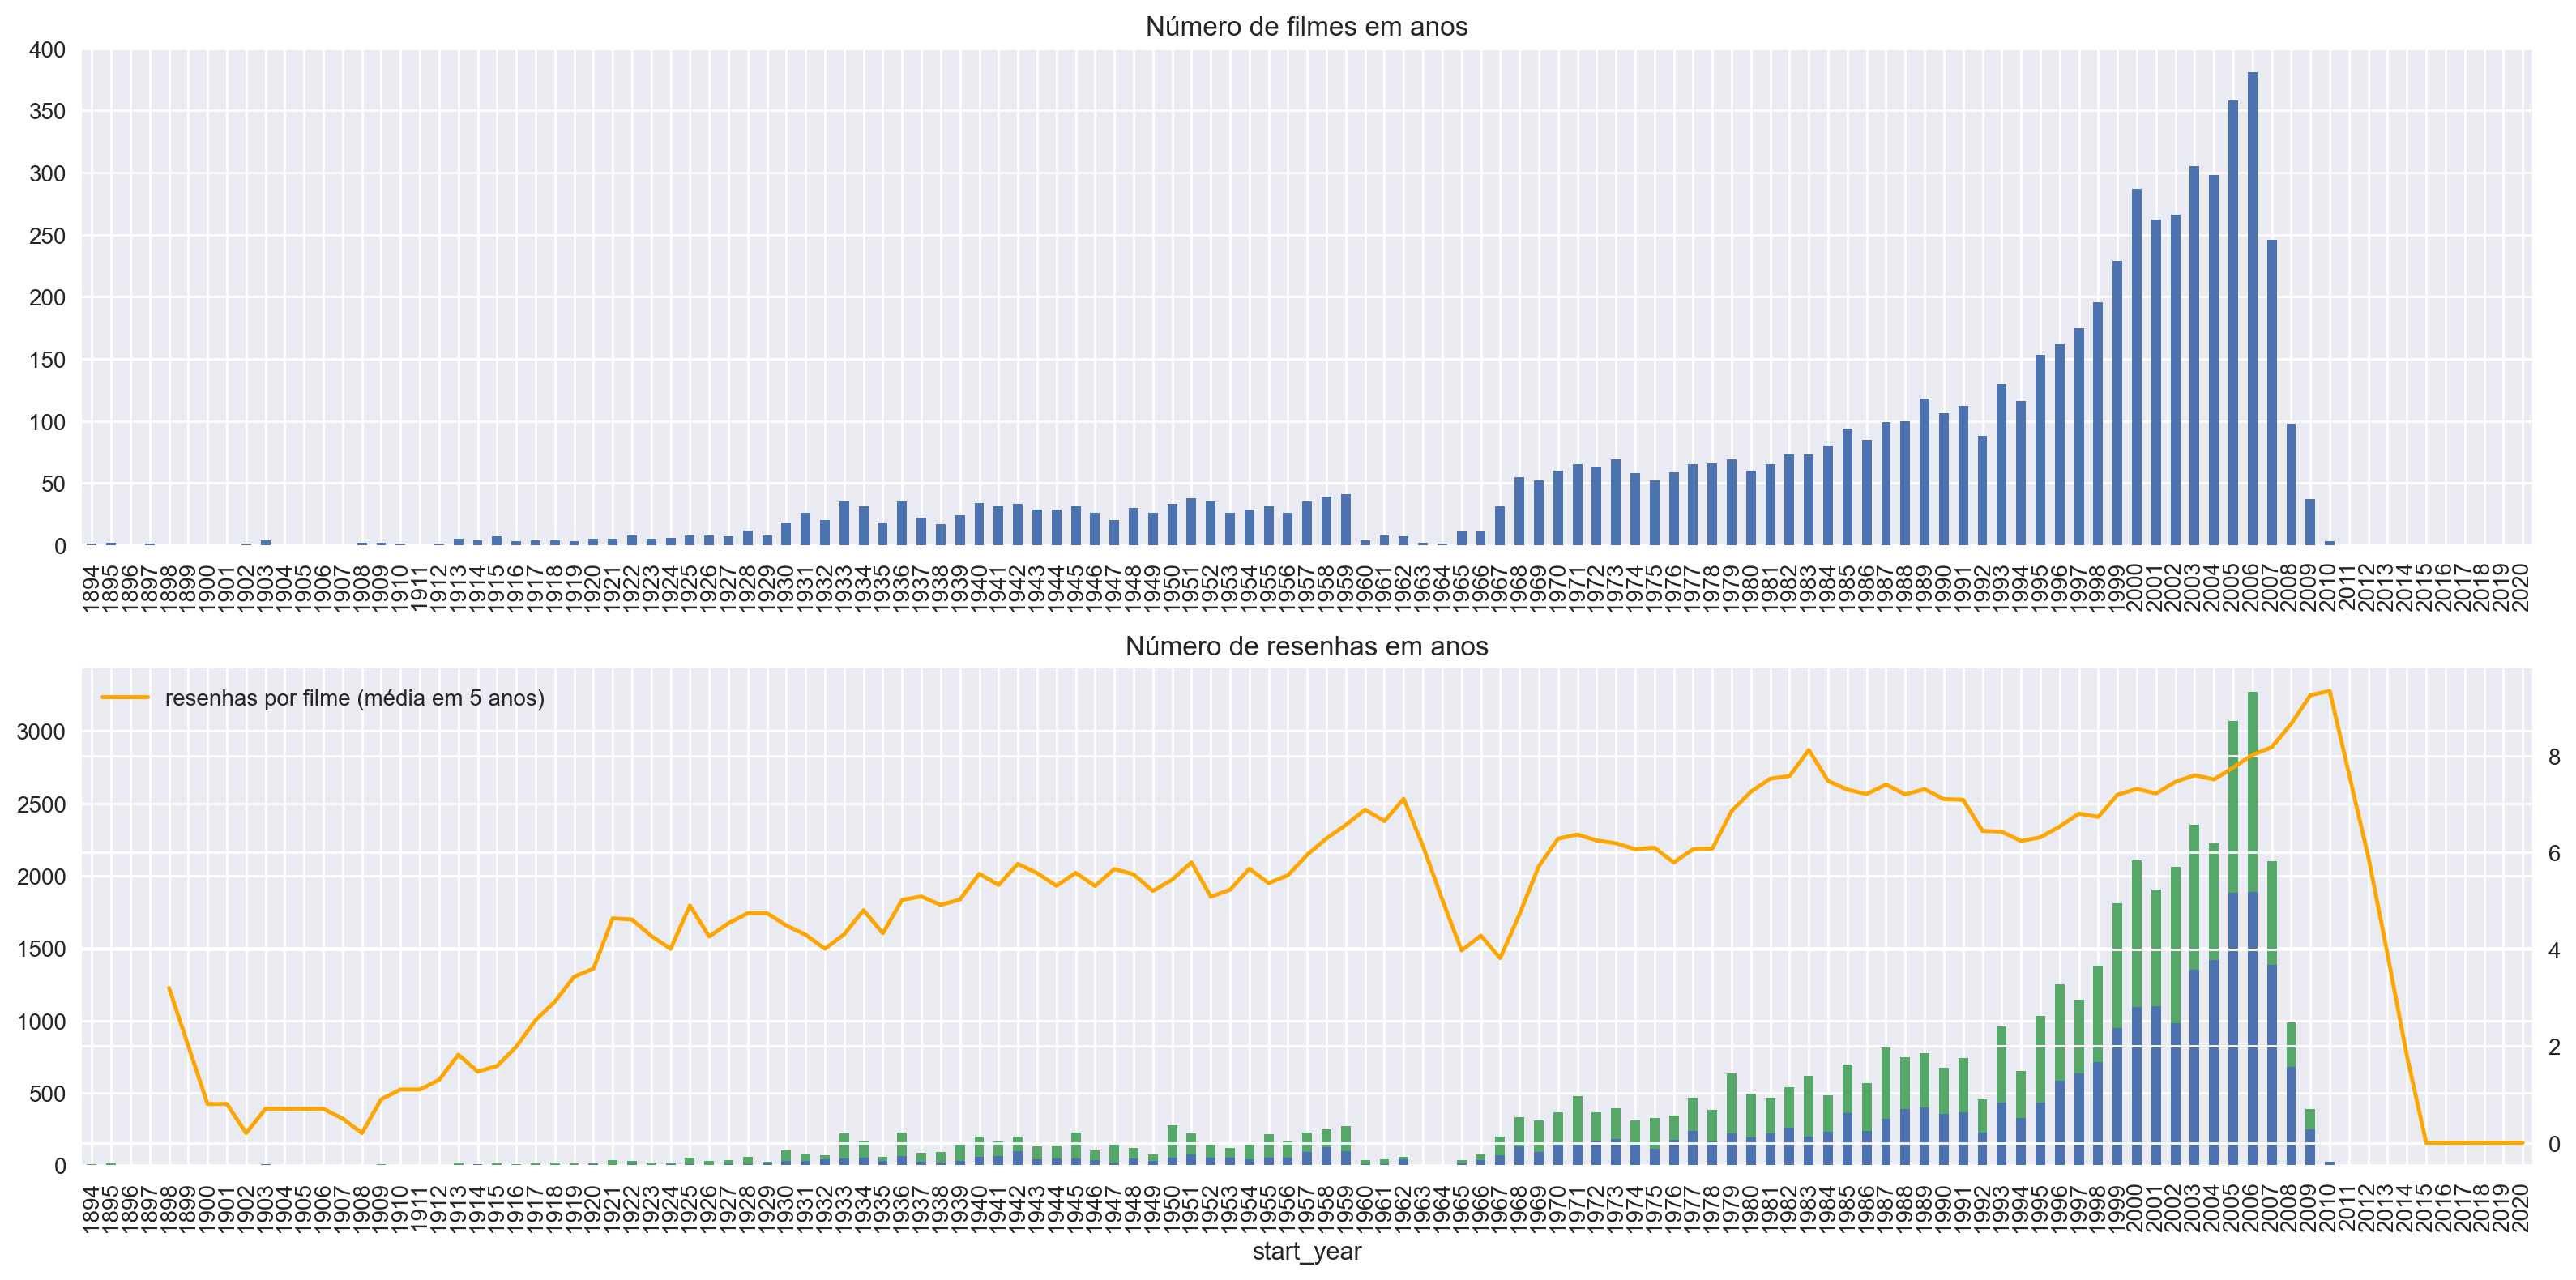

In [77]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8))

ax = axs[0]

dft1 = df_reviews[['tconst', 'start_year']].drop_duplicates() \
    ['start_year'].value_counts().sort_index()
dft1 = dft1.reindex(index=np.arange(dft1.index.min(), max(dft1.index.max(), 2021))).fillna(0)
dft1.plot(kind='bar', ax=ax)
ax.set_title('Número de filmes em anos')

ax = axs[1]

dft2 = df_reviews.groupby(['start_year', 'pos'])['pos'].count().unstack()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)

dft2.plot(kind='bar', stacked=True, label='#reviews (neg, pos)', ax=ax)

dft2 = df_reviews['start_year'].value_counts().sort_index()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)
dft3 = (dft2/dft1).fillna(0)
axt = ax.twinx()
dft3.reset_index(drop=True).rolling(5).mean().plot(color='orange', label='resenhas por filme (média em 5 anos)', ax=axt)

lines, labels = axt.get_legend_handles_labels()
ax.legend(lines, labels, loc='upper left')

ax.set_title('Número de resenhas em anos')

fig.tight_layout()

Vamos verificar a distribuição do número de resenhas por filme com a contagem exata e o EDK (Estimativa de densidade kernel - só para saber como pode diferir da contagem exata)

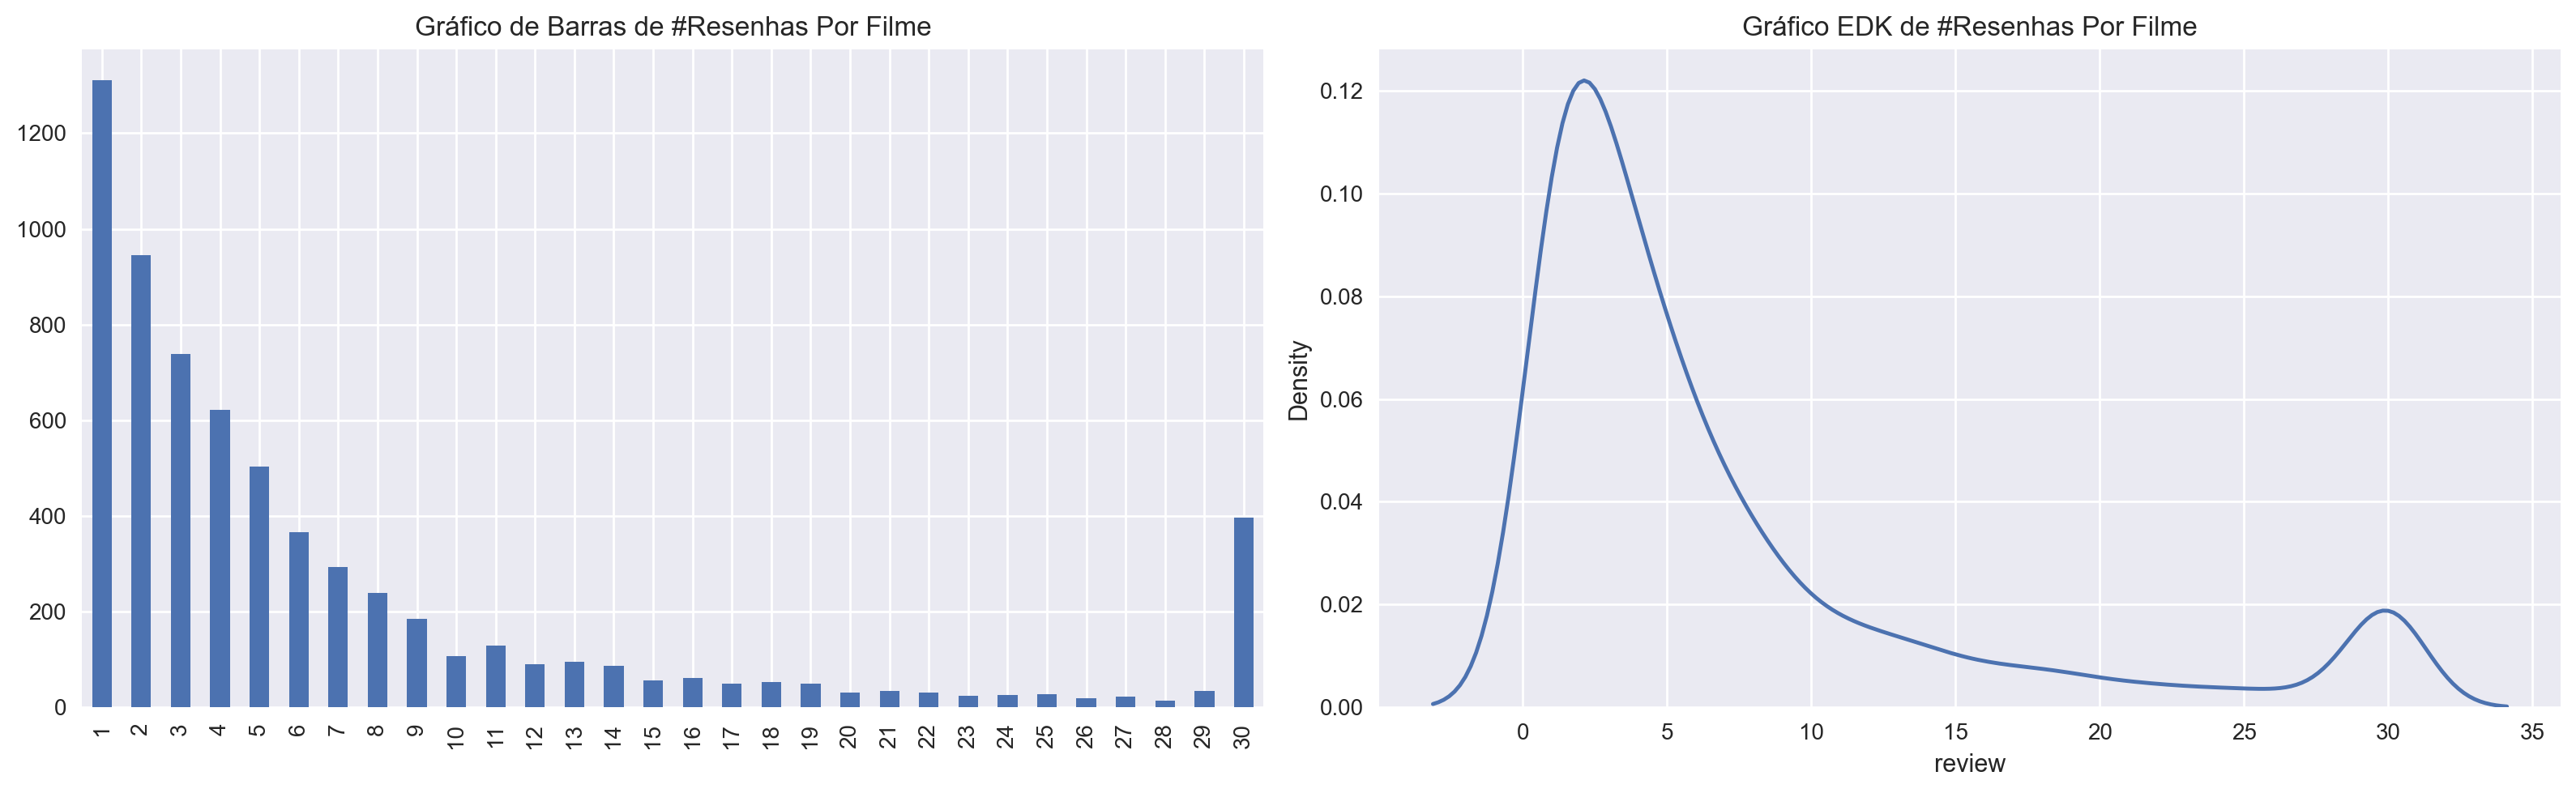

In [78]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5))

ax = axs[0]
dft = df_reviews.groupby('tconst')['review'].count() \
    .value_counts() \
    .sort_index()
dft.plot.bar(ax=ax)
ax.set_title('Gráfico de Barras de #Resenhas Por Filme')

ax = axs[1]
dft = df_reviews.groupby('tconst')['review'].count()
sns.kdeplot(dft, ax=ax)
ax.set_title('Gráfico EDK de #Resenhas Por Filme')

fig.tight_layout()

### Análise de equilíbrio de classes da variável alvo 

In [79]:
class_counts = df_reviews['pos'].value_counts().sort_index()
class_share = df_reviews['pos'].value_counts(normalize=True).sort_index()

print('Contagem por classe:')
print(class_counts)

print('\nProporção por classe:')
print(class_share)

class_by_part = pd.crosstab(
    df_reviews['ds_part'],
    df_reviews['pos'],
    normalize='index'
)

display(class_by_part)

Contagem por classe:
0    23680
1    23560
Name: pos, dtype: int64

Proporção por classe:
0    0.50127
1    0.49873
Name: pos, dtype: float64


pos,0,1
ds_part,,
test,0.501852,0.498148
train,0.500695,0.499305


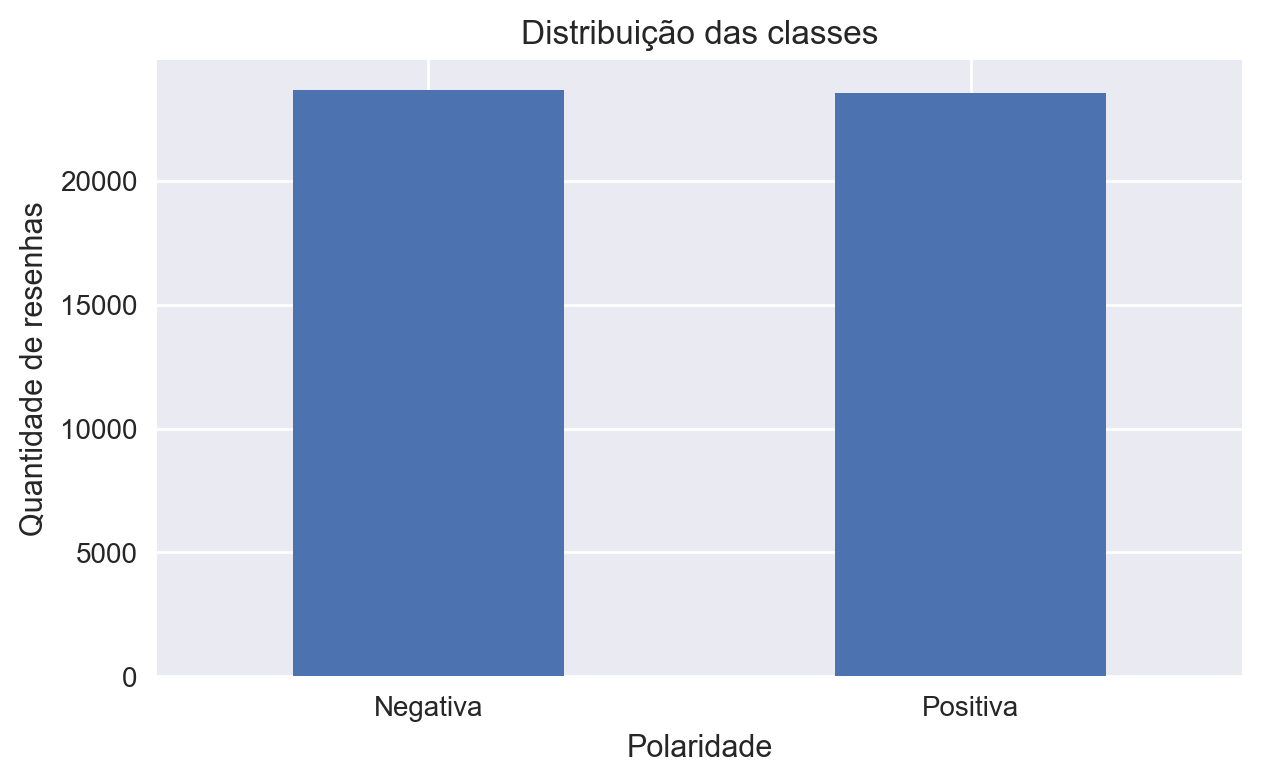

In [80]:
ax = class_counts.rename(
    index={0: 'Negativa', 1: 'Positiva'}
).plot(kind='bar', figsize=(7, 4))

ax.set_title('Distribuição das classes')
ax.set_xlabel('Polaridade')
ax.set_ylabel('Quantidade de resenhas')
plt.xticks(rotation=0)
plt.show()

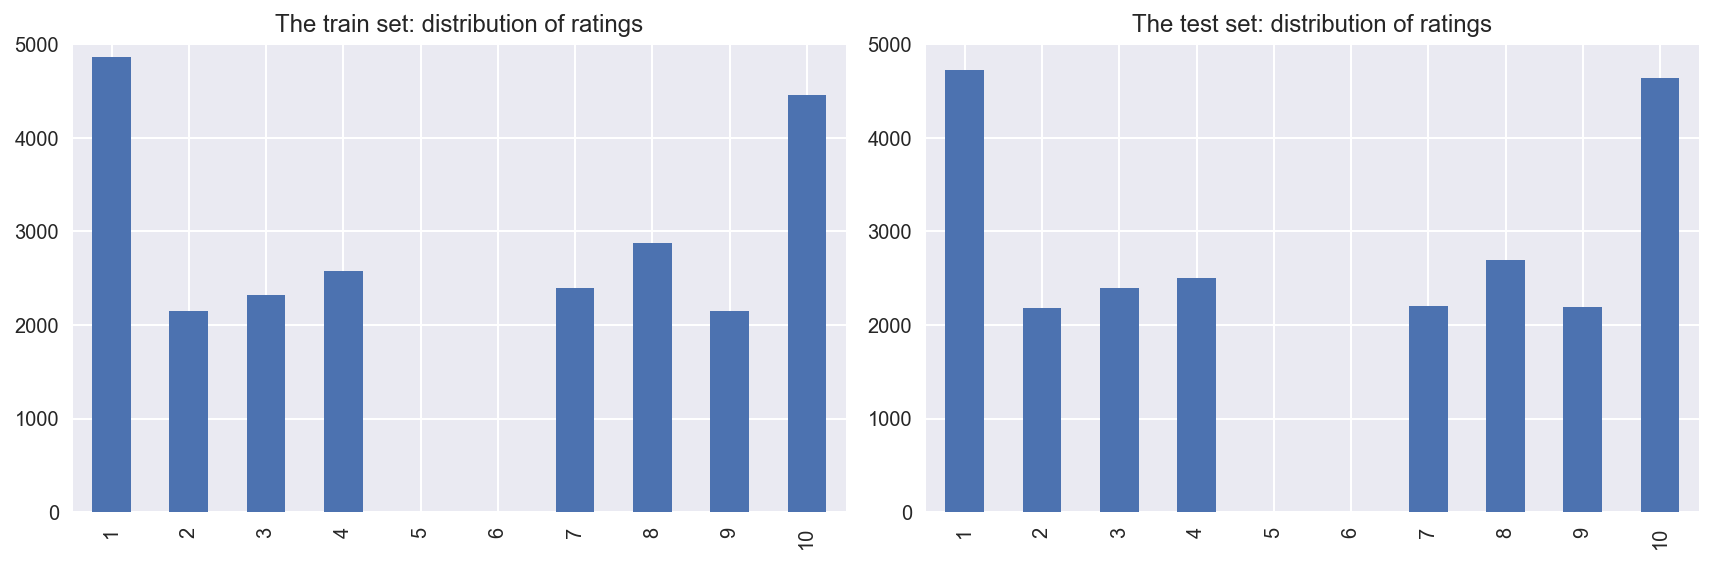

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

ax = axs[0]
dft = df_reviews.query('ds_part == "train"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('O conjunto de treinamento: distribuição de classificações')

ax = axs[1]
dft = df_reviews.query('ds_part == "test"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('O conjunto de teste: distribuição de classificações')

fig.tight_layout()

Distribuição de resenhas negativas e positivas ao longo dos anos para duas partes do conjunto de dados

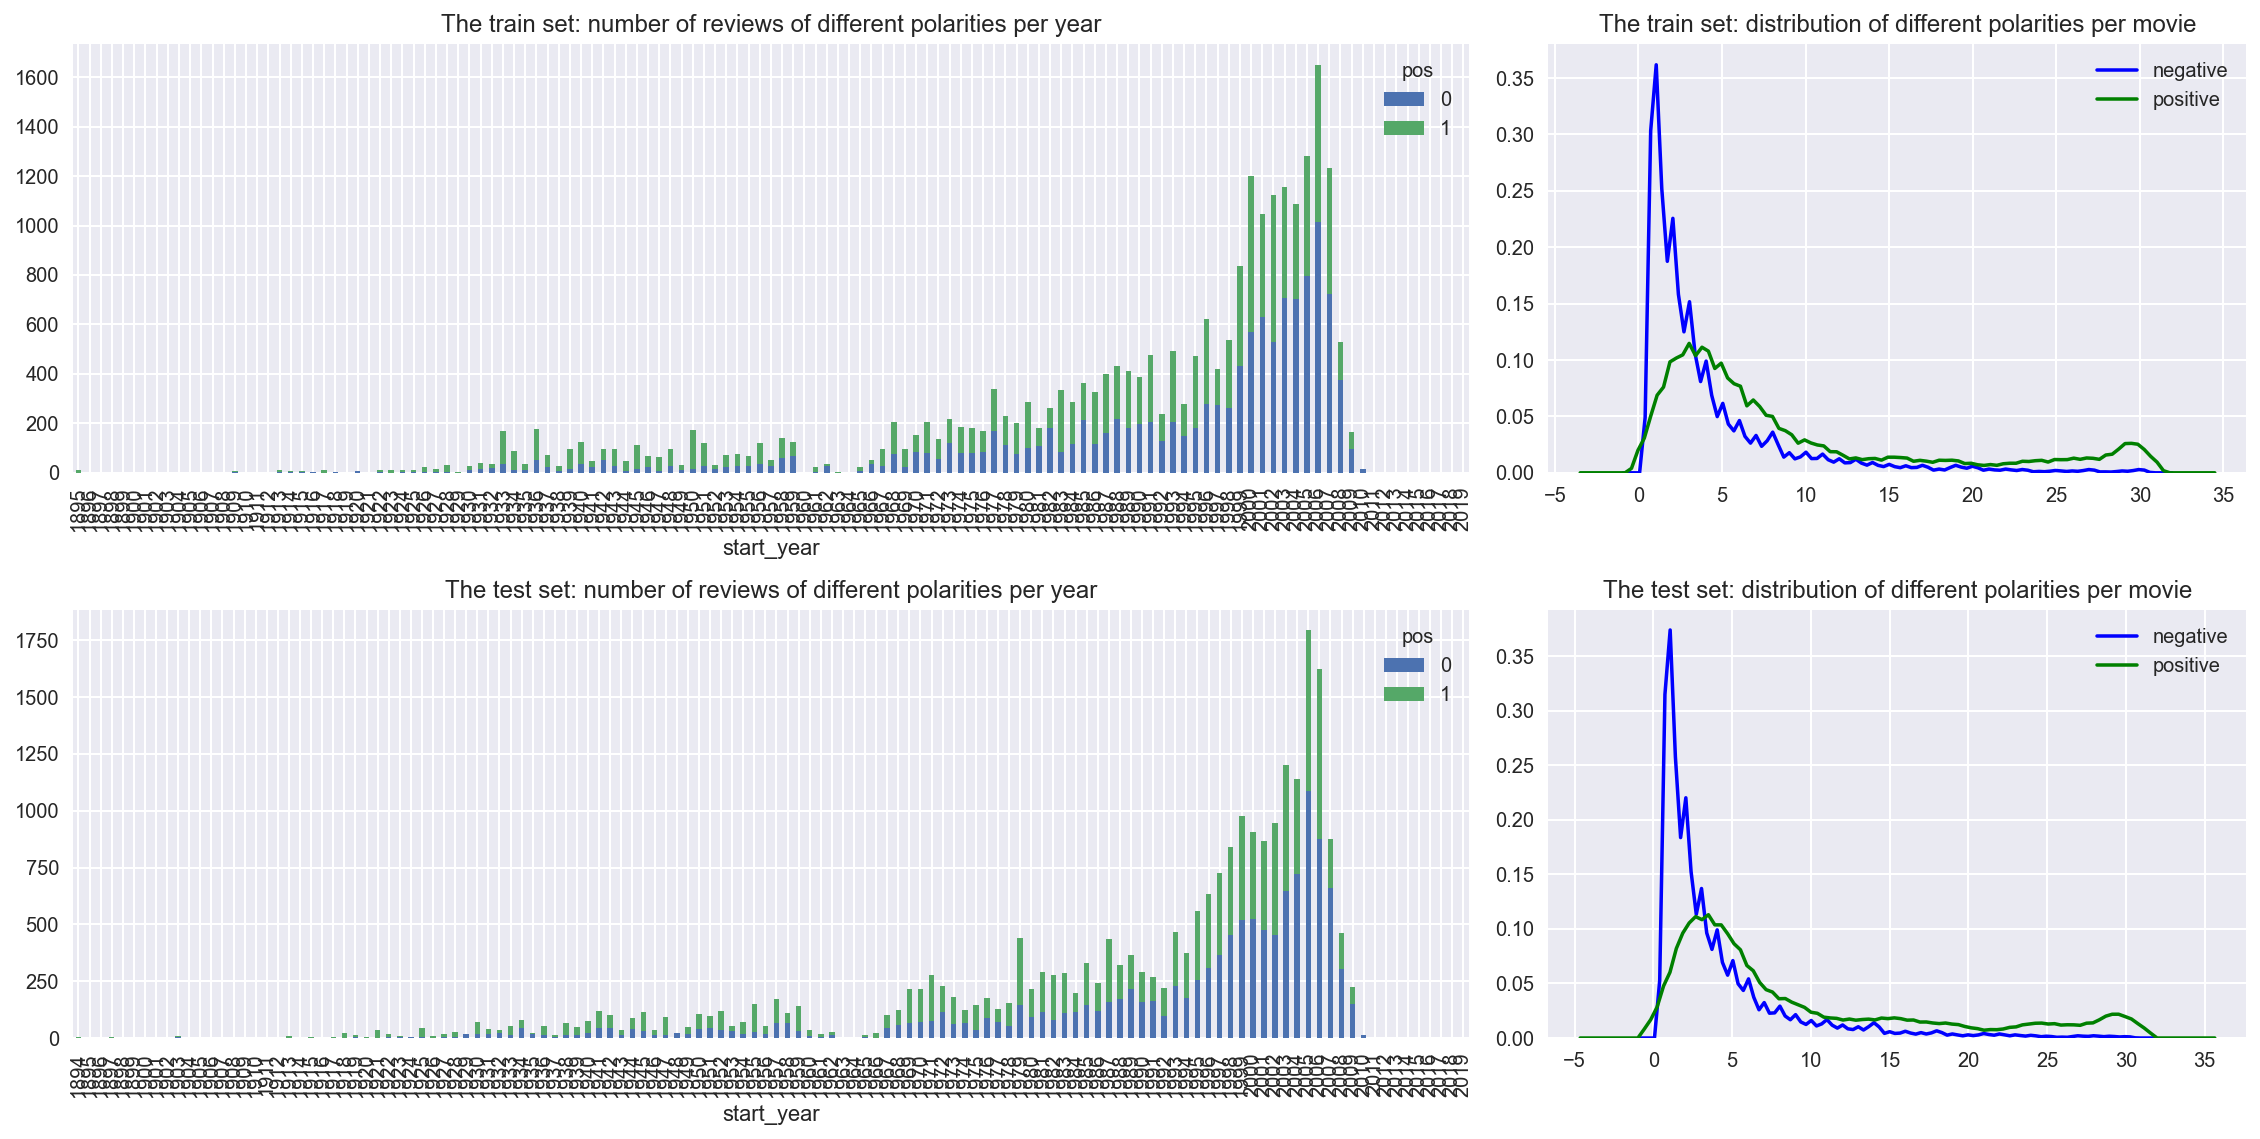

In [14]:
fig, axs = plt.subplots(2, 2, figsize=(16, 8), gridspec_kw=dict(width_ratios=(2, 1), height_ratios=(1, 1)))

ax = axs[0][0]

dft = df_reviews.query('ds_part == "train"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('O conjunto de treinamento: número de resenhas de diferentes polaridades por ano')

ax = axs[0][1]

dft = df_reviews.query('ds_part == "train"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
ax.legend()
ax.set_title('O conjunto de treinamento: distribuição de diferentes polaridades por filme')

ax = axs[1][0]

dft = df_reviews.query('ds_part == "test"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('O conjunto de teste: número de resenhas de diferentes polaridades por ano')

ax = axs[1][1]

dft = df_reviews.query('ds_part == "test"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
ax.legend()
ax.set_title('The test set: distribution of different polarities per movie')

fig.tight_layout()

Comprimento das resenhas positivas e negativas

In [86]:
# Criando uma cópia do dataset limpo para evitar alterações acidentais no original
df_review_lengths = df_reviews[['review', 'pos']].copy()

# Calculando o comprimento das resenhas em número de palavras
df_review_lengths['word_count'] = (
    df_review_lengths['review']
    .str.split() # Divide a review numa lista de palavras separadas por espaço
    .str.len() # Conta o número de palavras na lista
)

# Mapenado pos para labels mais descritivas
df_review_lengths['sentiment'] = df_review_lengths['pos'].map({
    0: 'Negative', 
    1: 'Positive'
}) 

# Exibindo informação dos dados
df_review_lengths.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47240 entries, 0 to 47239
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   review      47240 non-null  object
 1   pos         47240 non-null  int64 
 2   word_count  47240 non-null  int64 
 3   sentiment   47240 non-null  object
dtypes: int64(2), object(2)
memory usage: 1.4+ MB


In [82]:
# Gerando estatísticas descritivas do comprimento das resenhas por sentimento

length_stats = (
    df_review_lengths
    .groupby('sentiment')['word_count']
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    .round(2)
)

display(length_stats)

,count,mean,median,std,min,max
sentiment,,,,,,
Negative,23680,227.58,173,163.51,4,1491
Positive,23560,231.52,171,176.58,10,2459


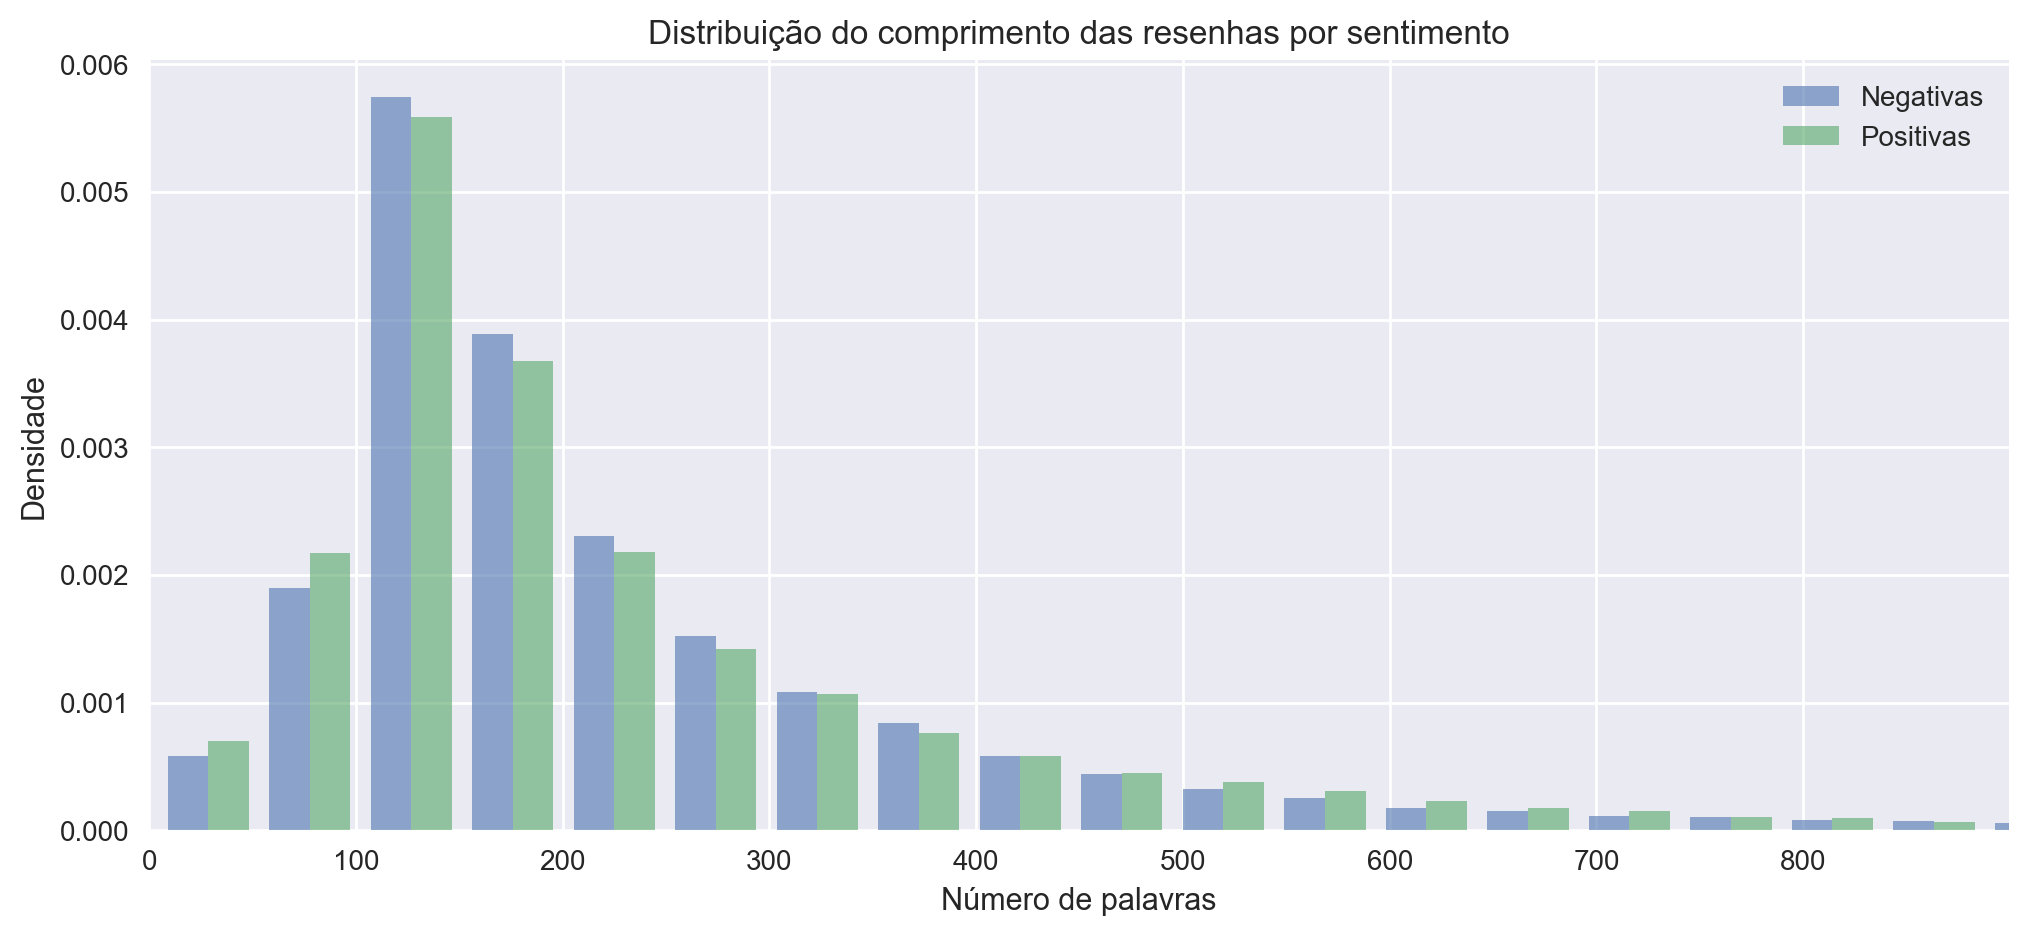

In [87]:
plt.figure(figsize=(12, 5))

negative = df_review_lengths.query(
    "sentiment == 'Negative'"
)['word_count']

positive = df_review_lengths.query(
    "sentiment == 'Positive'"
)['word_count']

plt.hist(
    [negative, positive],
    bins=50,
    density=True,
    alpha=0.6,
    label=['Negativas', 'Positivas']
)

plt.xlim(0, df_review_lengths['word_count'].quantile(0.99))
plt.title('Distribuição do comprimento das resenhas por sentimento')
plt.xlabel('Número de palavras')
plt.ylabel('Densidade')
plt.legend()
plt.show()

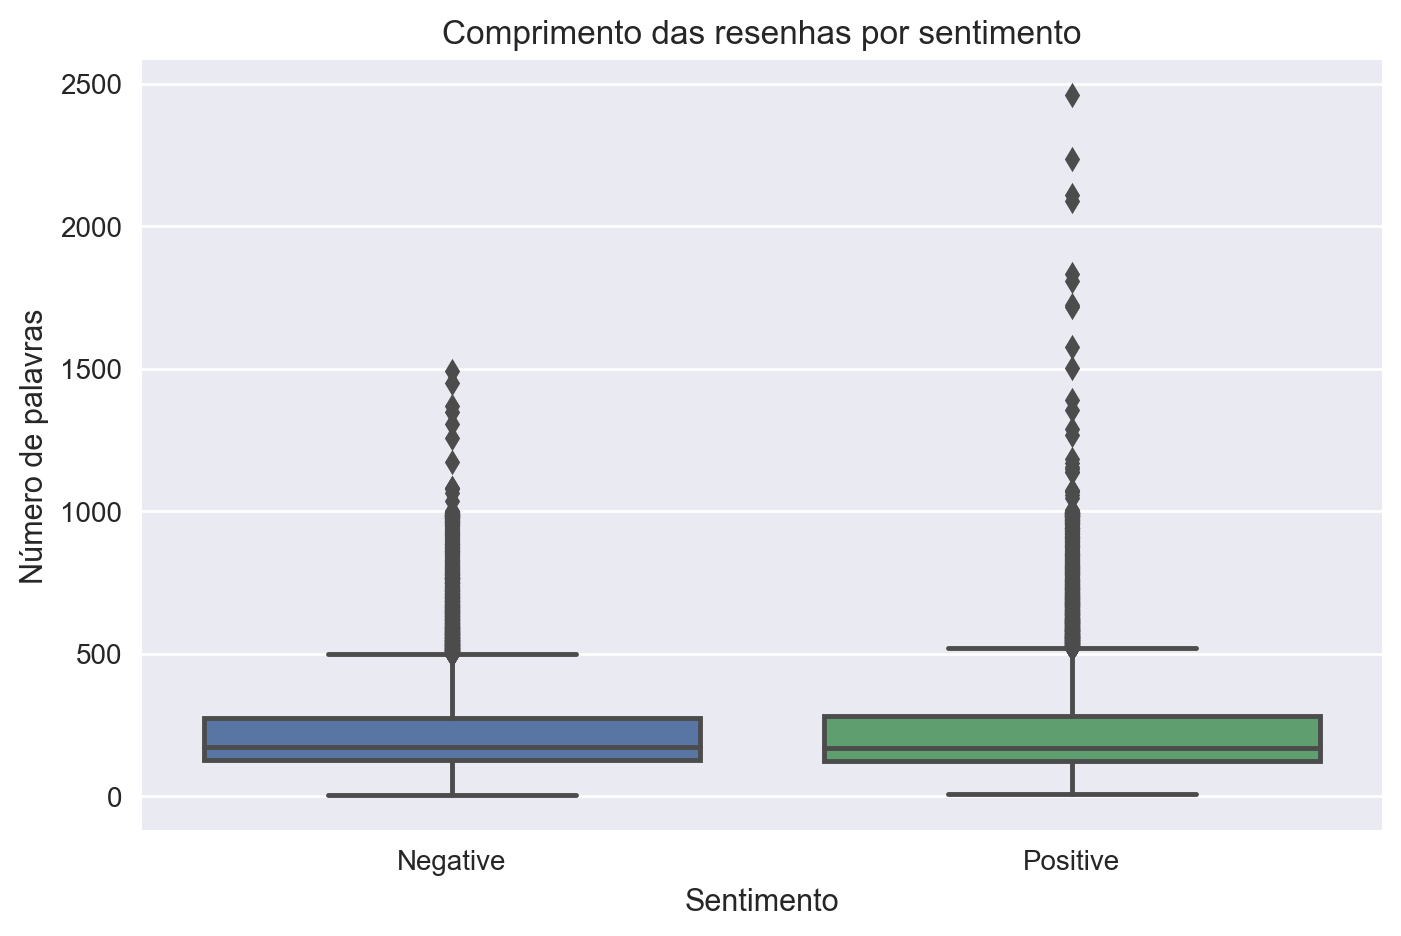

In [85]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_review_lengths,
    x='sentiment',
    y='word_count'
)

plt.title('Comprimento das resenhas por sentimento')
plt.xlabel('Sentimento')
plt.ylabel('Número de palavras')
plt.show()

### Conclusão AED

O conjunto apresenta equilíbrio entre as classes, com 50,13% de avaliações negativas e 49,87% positivas. Essa proporção também se mantém nos conjuntos de treinamento e teste, não indicando necessidade de técnicas específicas de balanceamento.

A análise do comprimento das resenhas revelou distribuições semelhantes entre os sentimentos: as negativas apresentam média de 227,58 palavras e mediana de 173, enquanto as positivas apresentam média de 231,52 e mediana de 171. Portanto, o comprimento dos textos, isoladamente, não demonstra capacidade relevante de distinguir as classes.

**Implicações para a modelagem:** podemos iniciar o treinamento sem reamostragem das classes ou aplicação de pesos específicos.

## Procedimento de Avaliação

Compondo uma rotina de avaliação que pode ser utilizada para todos os modelos deste projeto

**Observação:** Verifiquei alguns problemas com a função `evaluate_model()` fornecida em pré-código ao utiliza-lá com o modelo dummy (ver *Modelo 0 - Constante*). Por isso acrescentei alguns comentários a função original e uma versão revisada dela abaixo.

Questões identificadas com a função e possíveis melhorias:

* A função não armazena corretamente acurácia e o score f1 em `eval_stats` (corrigido na versão enviada por Vinícius, abaixo)
* A função não retorna os resultados, dificultando a comparação entre os modelos

**E uma questão metodológica:**

Numa classificação binária, a função utiliza o f1-score usa por padrão a classe positiva. A função de avaliação mantém o comportamento padrão. Como f1 é nossa métrica de otimização, utilizar um f1 orientado à classe positiva diverge um pouco do objetivo de negócios de avaliar resenhas negativas, apontado no enunciado. 

Além disso, ao avaliar um modelo dummy que sempre escolhe a classe mais frequente (a classe negativa, no caso do dataset deste projeto), obtivemos um `f1 = 0`, que é pouco útil como baseline para os próximos teste. Mas ao ajustar o f1 com o parâmetro `pos-label=0`, obtivemos um `f1 ~= 0.67`, que passa a ser um ponto de comparação para avaliação dos próximos modelos.

In [102]:
import sklearn.metrics as metrics

def evaluate_model(model, train_features, train_target, test_features, test_target):
    
    eval_stats = {}
    
    fig, axs = plt.subplots(1, 3, figsize=(20, 6)) 
    
    for type, features, target in (('train', train_features, train_target), ('test', test_features, test_target)):
        
        eval_stats[type] = {}
    
        pred_target = model.predict(features)
        pred_proba = model.predict_proba(features)[:, 1]
        
        # F1
        f1_thresholds = np.arange(0, 1.01, 0.05)
        f1_scores = [metrics.f1_score(target, pred_proba>=threshold) for threshold in f1_thresholds]
        
        # ROC
        fpr, tpr, roc_thresholds = metrics.roc_curve(target, pred_proba)
        roc_auc = metrics.roc_auc_score(target, pred_proba)    
        eval_stats[type]['ROC AUC'] = roc_auc

        # Curva de precisão-revocação
        precision, recall, pr_thresholds = metrics.precision_recall_curve(target, pred_proba)
        aps = metrics.average_precision_score(target, pred_proba)
        eval_stats[type]['APS'] = aps
        
        if type == 'train':
            color = 'blue'
        else:
            color = 'green'

        # Valor F1
        ax = axs[0]
        max_f1_score_idx = np.argmax(f1_scores)
        ax.plot(f1_thresholds, f1_scores, color=color, label=f'{type}, max={f1_scores[max_f1_score_idx]:.2f} @ {f1_thresholds[max_f1_score_idx]:.2f}')
        # definindo cruzamentos para alguns limiares
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(f1_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(f1_thresholds[closest_value_idx], f1_scores[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])    
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('threshold')
        ax.set_ylabel('F1')
        ax.legend(loc='lower center')
        ax.set_title(f'Valor F1') 

        # ROC
        ax = axs[1]    
        ax.plot(fpr, tpr, color=color, label=f'{type}, ROC AUC={roc_auc:.2f}')
        # setting crosses for some thresholds
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(roc_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'            
            ax.plot(fpr[closest_value_idx], tpr[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.plot([0, 1], [0, 1], color='grey', linestyle='--')
        ax.set_xlim([-0.02, 1.02])    
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('FPR')
        ax.set_ylabel('TPR')
        ax.legend(loc='lower center')        
        ax.set_title(f'Curva ROC')
        
        # Curva de precisão-revocação
        ax = axs[2]
        ax.plot(recall, precision, color=color, label=f'{type}, AP={aps:.2f}')
        # definindo cruzamentos para alguns limiares
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(pr_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(recall[closest_value_idx], precision[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])    
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('recall')
        ax.set_ylabel('precision')
        ax.legend(loc='lower center')
        ax.set_title(f'PRC')        

        eval_stats[type]['Accuracy'] = metrics.accuracy_score(target, pred_target)
    
    df_eval_stats = pd.DataFrame(eval_stats)
    df_eval_stats = df_eval_stats.round(2)
    df_eval_stats = df_eval_stats.reindex(index=('Acurácia', 'F1', 'APS', 'ROC AUC'))
    
    print(df_eval_stats)
    
    return

Versão corrigida enviada pelo tutor Vinicius Simm:

In [ ]:
def evaluate_model_vinicius(model, train_features, train_target, test_features, test_target):
    
    eval_stats = {}
    
    fig, axs = plt.subplots(1, 3, figsize=(20, 6)) 
    
    for type, features, target in (('train', train_features, train_target), ('test', test_features, test_target)):
        
        eval_stats[type] = {}
    
        pred_target = model.predict(features)
        pred_proba = model.predict_proba(features)[:, 1]
        
        # F1
        f1_thresholds = np.arange(0, 1.01, 0.05)
        f1_scores = [metrics.f1_score(target, pred_proba>=threshold) for threshold in f1_thresholds]
        
        # ROC
        fpr, tpr, roc_thresholds = metrics.roc_curve(target, pred_proba)
        roc_auc = metrics.roc_auc_score(target, pred_proba)    
        eval_stats[type]['ROC AUC'] = roc_auc

        # Curva de precisão-revocação
        precision, recall, pr_thresholds = metrics.precision_recall_curve(target, pred_proba)
        aps = metrics.average_precision_score(target, pred_proba)
        eval_stats[type]['APS'] = aps
        
        if type == 'train':
            color = 'blue'
        else:
            color = 'green'

        # Valor F1
        ax = axs[0]
        max_f1_score_idx = np.argmax(f1_scores)
        ax.plot(f1_thresholds, f1_scores, color=color, label=f'{type}, max={f1_scores[max_f1_score_idx]:.2f} @ {f1_thresholds[max_f1_score_idx]:.2f}')
        # definindo cruzamentos para alguns limiares
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(f1_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(f1_thresholds[closest_value_idx], f1_scores[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])    
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('threshold')
        ax.set_ylabel('F1')
        ax.legend(loc='lower center')
        ax.set_title(f'Valor F1') 

        # ROC
        ax = axs[1]    
        ax.plot(fpr, tpr, color=color, label=f'{type}, ROC AUC={roc_auc:.2f}')
        # setting crosses for some thresholds
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(roc_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'            
            ax.plot(fpr[closest_value_idx], tpr[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.plot([0, 1], [0, 1], color='grey', linestyle='--')
        ax.set_xlim([-0.02, 1.02])    
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('FPR')
        ax.set_ylabel('TPR')
        ax.legend(loc='lower center')        
        ax.set_title(f'Curva ROC')
        
        # Curva de precisão-revocação
        ax = axs[2]
        ax.plot(recall, precision, color=color, label=f'{type}, AP={aps:.2f}')
        # definindo cruzamentos para alguns limiares
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(pr_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(recall[closest_value_idx], precision[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])    
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('recall')
        ax.set_ylabel('precision')
        ax.legend(loc='lower center')
        ax.set_title(f'PRC')        

        eval_stats[type]['Accuracy'] = metrics.accuracy_score(target, pred_target)
        eval_stats[type]['F1'] = metrics.f1_score(target, pred_target)
    
    df_eval_stats = pd.DataFrame(eval_stats)
    df_eval_stats = df_eval_stats.round(2)
    df_eval_stats = df_eval_stats.reindex(index=('Accuracy', 'F1', 'APS', 'ROC AUC'))
    
    print(df_eval_stats)
    
    return

Minha versão com os ajustes comentados anteriormente:

In [113]:
# Revisão da função de avaliação para incluir avaliação de f1 focada na classe negativa (0)

def evaluate_model_v2(model, train_features, train_target, test_features, test_target):
    
    eval_stats = {}
    
    fig, axs = plt.subplots(1, 4, figsize=(24, 6))

    # tornando a identificação de classe positiva mais robusta
    positive_class_idx = list(model.classes_).index(1)
    
    for type, features, target in (('train', train_features, train_target), ('test', test_features, test_target)):
        
        eval_stats[type] = {}
    
        pred_target = model.predict(features)
        pred_proba = model.predict_proba(features)[:, positive_class_idx]
        
        # F1
        f1_thresholds = np.arange(0, 1.01, 0.05)
        f1_scores = [metrics.f1_score(target, pred_proba>=threshold) for threshold in f1_thresholds]
        eval_stats[type]['F1'] = metrics.f1_score(target, pred_target)

        f1_scores_negative = [ metrics.f1_score(target,pred_proba >= threshold,pos_label=0) for threshold in f1_thresholds]
        eval_stats[type]['F1 (negative)'] = metrics.f1_score(target, pred_target, pos_label=0)
        
        # ROC
        fpr, tpr, roc_thresholds = metrics.roc_curve(target, pred_proba,)
        roc_auc = metrics.roc_auc_score(target, pred_proba)    
        eval_stats[type]['ROC AUC'] = roc_auc

        # Curva de precisão-revocação
        precision, recall, pr_thresholds = metrics.precision_recall_curve(target, pred_proba)
        aps = metrics.average_precision_score(target, pred_proba)
        eval_stats[type]['APS'] = aps
        
        if type == 'train':
            color = 'blue'
        else:
            color = 'green'

        # Valor F1 default
        ax = axs[0]
        max_f1_score_idx = np.argmax(f1_scores)
        ax.plot(f1_thresholds, f1_scores, color=color, label=f'{type}, max={f1_scores[max_f1_score_idx]:.2f} @ {f1_thresholds[max_f1_score_idx]:.2f}')
        # definindo cruzamentos para alguns limiares
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(f1_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(f1_thresholds[closest_value_idx], f1_scores[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])    
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('threshold')
        ax.set_ylabel('F1')
        ax.legend(loc='lower center')
        ax.set_title(f'Valor F1') 

        # F1 da classe negativa
        ax = axs[1]

        max_f1_negative_idx = np.argmax(f1_scores_negative)

        ax.plot(
            f1_thresholds,
            f1_scores_negative,
            color=color,
            label=f'{type}, max={f1_scores_negative[max_f1_negative_idx]:.2f} @ {f1_thresholds[max_f1_negative_idx]:.2f}'
        )

        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(f1_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(
                f1_thresholds[closest_value_idx],
                f1_scores_negative[closest_value_idx],
                color=marker_color,
                marker='X',
                markersize=7
            )

        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('threshold')
        ax.set_ylabel('F1')
        ax.legend(loc='lower center')
        ax.set_title('F1 — Classe negativa (0)')

        # ROC
        ax = axs[2]    
        ax.plot(fpr, tpr, color=color, label=f'{type}, ROC AUC={roc_auc:.2f}')
        # setting crosses for some thresholds
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(roc_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'            
            ax.plot(fpr[closest_value_idx], tpr[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.plot([0, 1], [0, 1], color='grey', linestyle='--')
        ax.set_xlim([-0.02, 1.02])    
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('FPR')
        ax.set_ylabel('TPR')
        ax.legend(loc='lower center')        
        ax.set_title(f'Curva ROC')
        
        # Curva de precisão-revocação
        ax = axs[3]
        ax.plot(recall, precision, color=color, label=f'{type}, AP={aps:.2f}')
        # definindo cruzamentos para alguns limiares
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(pr_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(recall[closest_value_idx], precision[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])    
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('recall')
        ax.set_ylabel('precision')
        ax.legend(loc='lower center')
        ax.set_title(f'PRC')        

        eval_stats[type]['Accuracy'] = metrics.accuracy_score(target, pred_target)
        
    
    df_eval_stats = pd.DataFrame(eval_stats)
    df_eval_stats = df_eval_stats.round(2)
    df_eval_stats = df_eval_stats.reindex(index=('Accuracy', 'F1', 'F1 (negative)', 'APS', 'ROC AUC'))
    
    print(df_eval_stats)

    plt.tight_layout()
    plt.show()
    
    return df_eval_stats

In [119]:
# Criando df de resultados para comparação de modelos

df_results = pd.DataFrame(
    columns=[
        'Model',
        'Process',
        'Split',
        'Accuracy',
        'F1',
        'F1 (negative)',
        'APS',
        'ROC AUC'
    ]
)

## Normalização

Assumimos que todos os modelos abaixo aceitam textos em letras minúsculas e sem dígitos, sinais de pontuação, etc.

In [ ]:
## Criando uma função de normalização de texto para pré-processamento das resenhas
import re

def normalize_text(text):
    """
    Normaliza o texto de entrada, removendo pontuação e caracteres especiais, convertendo para minúsculas e removendo espaços extras.
    
    Parâmetros:
    text (str): O texto a ser normalizado.
    
    Retorna:
    str: O texto normalizado.
    """
    # converte o texto para letras minúsculas
    text = text.lower()

    # remove pontuação e caracteres especiais, mantendo apenas letras, espaços e apóstrofos
    pattern = r"[^a-zA-Z\s']"
    text = re.sub(pattern, ' ', text)

    # remove espaços extras e normaliza os espaços entre palavras
    text = ' '.join(text.split())

    return text

In [ ]:
# Aplicando a função de normalização de texto à coluna 'review' e criando uma nova coluna normalizada
df_reviews['review_norm'] = df_reviews['review'].apply(normalize_text)

In [ ]:
# Checando resultados da normalização
print("Exemplos de resenhas originais e normalizadas:")
display(df_reviews[['review', 'review_norm']].sample(5, random_state=RANDOM_STATE))

print("Valores nulos em 'review_norm':", df_reviews['review_norm'].isna().sum())
print()
print("Estatísticas de comprimento de 'review_norm':")
print(df_reviews['review_norm'].str.len().describe())

Exemplos de resenhas originais e normalizadas:


,review,review_norm
40402,A very disappointing film from Oliver Stone wh...,a very disappointing film from oliver stone wh...
36820,"I don't mean to sound pretentious here, but to...",i don't mean to sound pretentious here but to ...
36170,Coltrane and Idle are members of a bank robber...,coltrane and idle are members of a bank robber...
5881,I argued with myself whether to rent this or n...,i argued with myself whether to rent this or n...
10781,"Partially from the perceived need, one feels, ...",partially from the perceived need one feels to...


Valores nulos em 'review_norm': 0

Estatísticas de comprimento de 'review_norm':
count    47240.000000
mean      1252.893649
std        948.220030
min         30.000000
25%        670.000000
50%        929.000000
75%       1520.250000
max      13317.000000
Name: review_norm, dtype: float64


## Treinar / Testar Conjunto

Felizmente, todo o conjunto de dados já está dividido em partes de treinamento/teste. A opção correspondente é 'ds_part'.

In [92]:
df_reviews_train = df_reviews.query('ds_part == "train"').copy()
df_reviews_test = df_reviews.query('ds_part == "test"').copy()

train_target = df_reviews_train['pos']
test_target = df_reviews_test['pos']

print(df_reviews_train.shape)
print(df_reviews_test.shape)

(23757, 18)
(23483, 18)


In [97]:
# Separando as colunas de texto como features
text_train = df_reviews_train['review_norm']
text_test = df_reviews_test['review_norm']

print("Exemplos de resenhas de treino:")
display(text_train.sample(5, random_state=RANDOM_STATE))
print("Tamanho do conjunto de treino:", len(text_train))
print()
print("Exemplos de resenhas de teste:")
display(text_test.sample(5, random_state=RANDOM_STATE))
print("Tamanho do conjunto de teste:", len(text_test))

Exemplos de resenhas de treino:


4285    before seeing this movie i would've said that ...
8514    this is definitely one of the greatest disney ...
7201    jane russell proved to be a delightful musical...
8692    the peculiar charisma of martin kosleck brings...
8061    sure this movie wasn't like blocks inside man ...
Name: review_norm, dtype: object

Tamanho do conjunto de treino: 23757

Exemplos de resenhas de teste:


44610    this film brought a whole new meaning to that ...
29572    forget some the whiny and pointless comments l...
30091    pretty visuals and a lot of fights make not a ...
34474    saw the movie last night w o knowing anything ...
41999    of all the episodes of all series this one hol...
Name: review_norm, dtype: object

Tamanho do conjunto de teste: 23483


## Trabalhando com modelos

### Modelo 0 - Constante

In [98]:
from sklearn.dummy import DummyClassifier

In [99]:
# Instanciando o modelo DummyClassifier com a estratégia "most_frequent"
dummy_model = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)

# Criando vetores de features fictícios (dummy) para treino e teste, com o mesmo tamanho dos conjuntos de resenhas
dummy_train_features = np.zeros((len(text_train), 1))
dummy_test_features = np.zeros((len(text_test), 1))



In [100]:
# Treinando o modelo DummyClassifier
dummy_model.fit(dummy_train_features, train_target)

DummyClassifier(random_state=12345, strategy='most_frequent')

          train  test
Acurácia    NaN   NaN
F1          NaN   NaN
APS         0.5   0.5
ROC AUC     0.5   0.5


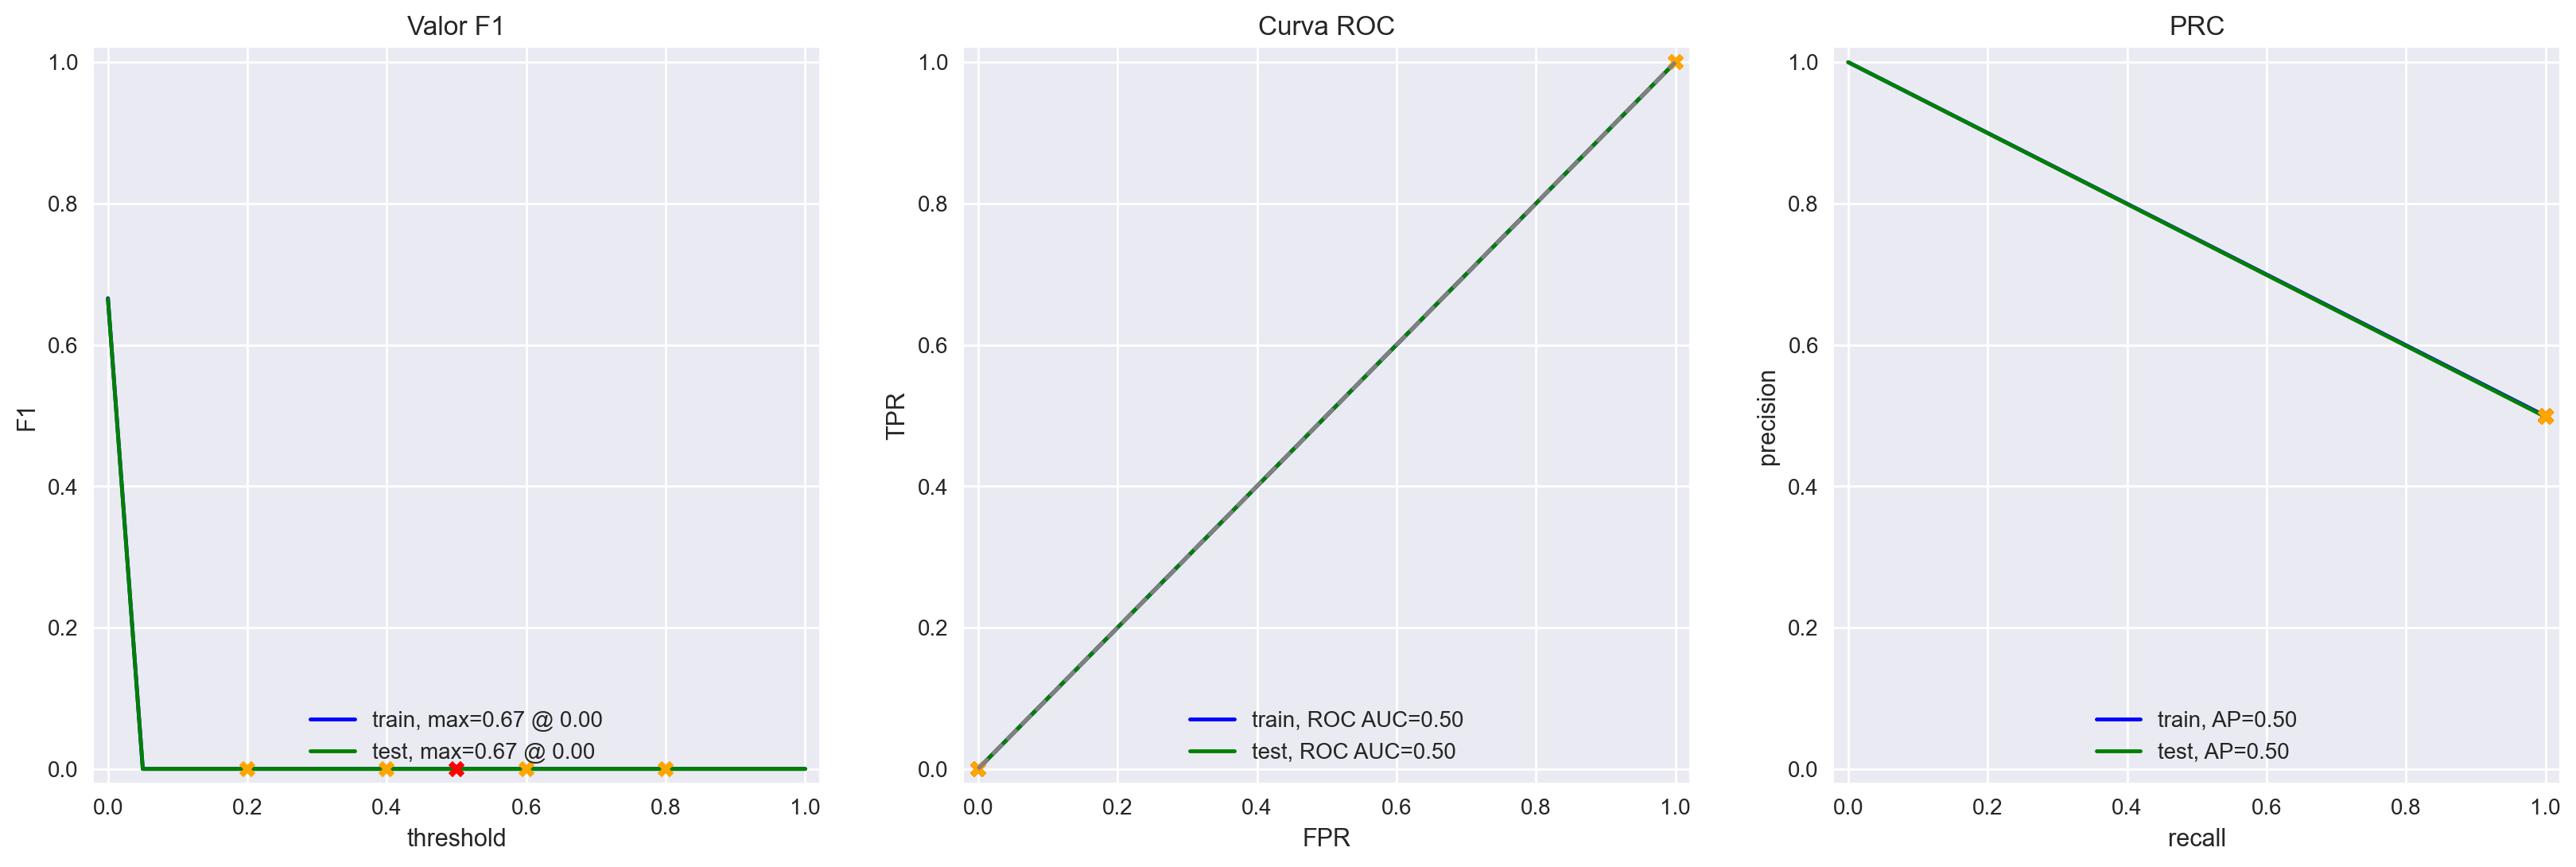

In [103]:
# Avaliando resultados do modelo DummyClassifier
evaluate_model(
    model=dummy_model,
    train_features=dummy_train_features,
    train_target=train_target,
    test_features=dummy_test_features,
    test_target=test_target
)

          train  test
Accuracy    0.5   0.5
F1          0.0   0.0
APS         0.5   0.5
ROC AUC     0.5   0.5


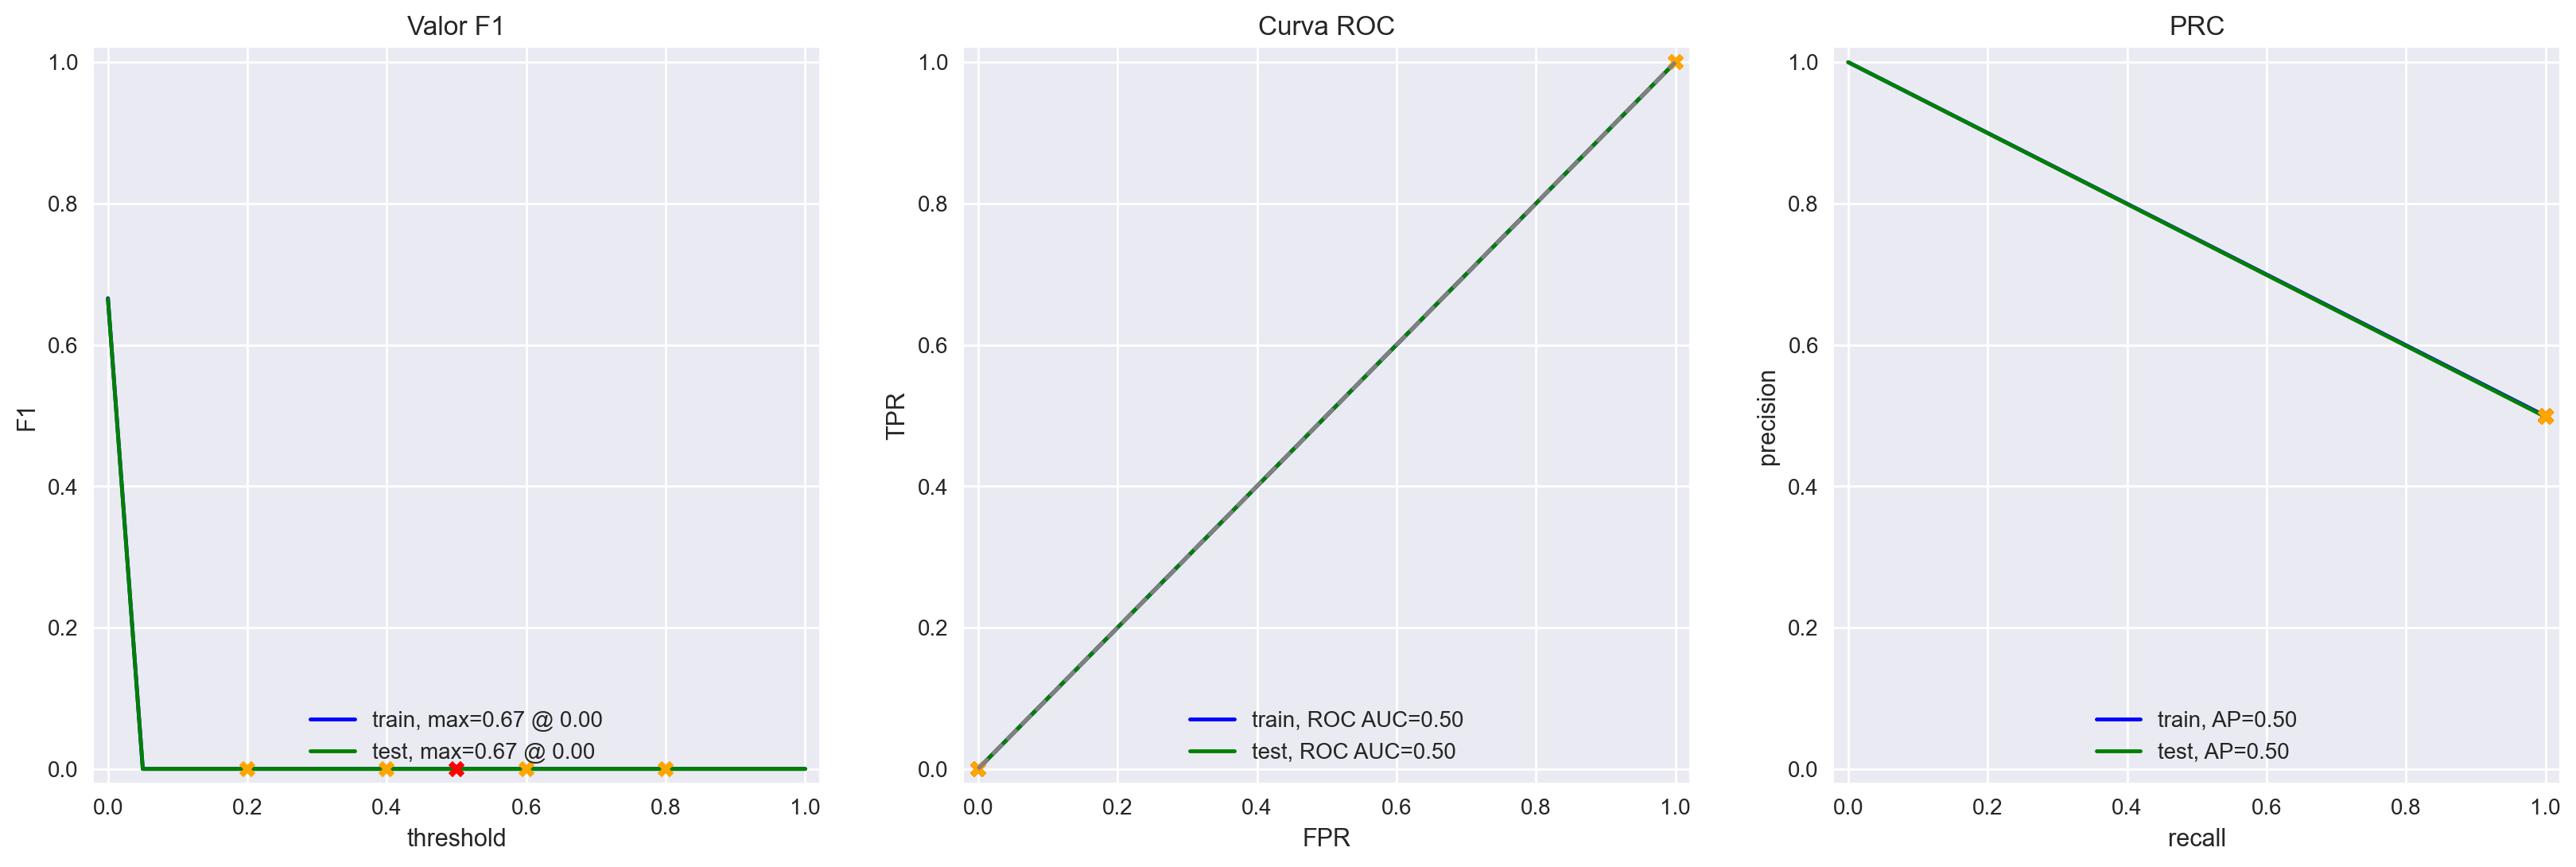

In [ ]:
evaluate_model_vinicius(
    model=dummy_model,
    train_features=dummy_train_features,
    train_target=train_target,
    test_features=dummy_test_features,
    test_target=test_target
)

In [ ]:
# Avaliando resultados do modelo DummyClassifier com métricas de acurácia e F1 fora da função evaluate_model para diagnóstico adicional
from sklearn.metrics import accuracy_score, f1_score

train_predictions = dummy_model.predict(dummy_train_features)
test_predictions = dummy_model.predict(dummy_test_features)

print('Treino')
print('Accuracy:', accuracy_score(train_target, train_predictions))
print('F1 (classe positiva):', f1_score(train_target, train_predictions, pos_label=1))
print('F1 (classe negativa):', f1_score(train_target, train_predictions, pos_label=0))

print('\nTeste')
print('Accuracy:', accuracy_score(test_target, test_predictions))
print('F1 (classe positiva):', f1_score(test_target, test_predictions, pos_label=1))
print('F1 (classe negativa):', f1_score(test_target, test_predictions, pos_label=0))

Treino
Accuracy: 0.5006945321378962
F1 (classe positiva): 0.0
F1 (classe negativa): 0.667283742847526

Teste
Accuracy: 0.5018524038666269
F1 (classe positiva): 0.0
F1 (classe negativa): 0.6683112169672224


A função de avaliação do pré-código parece não estar registrando corretamente os valores de Acurácia e F1 na tabela de resultados e também não da um retorno para salvar e comparar os resultados mais a frente. Para corrigir essas questões, usaremos uma versão revisada da função. A justificativa da revisão se encontra na seção **Preparação para avaliação**

               train  test
Accuracy        0.50  0.50
F1              0.00  0.00
F1 (negative)   0.67  0.67
APS             0.50  0.50
ROC AUC         0.50  0.50


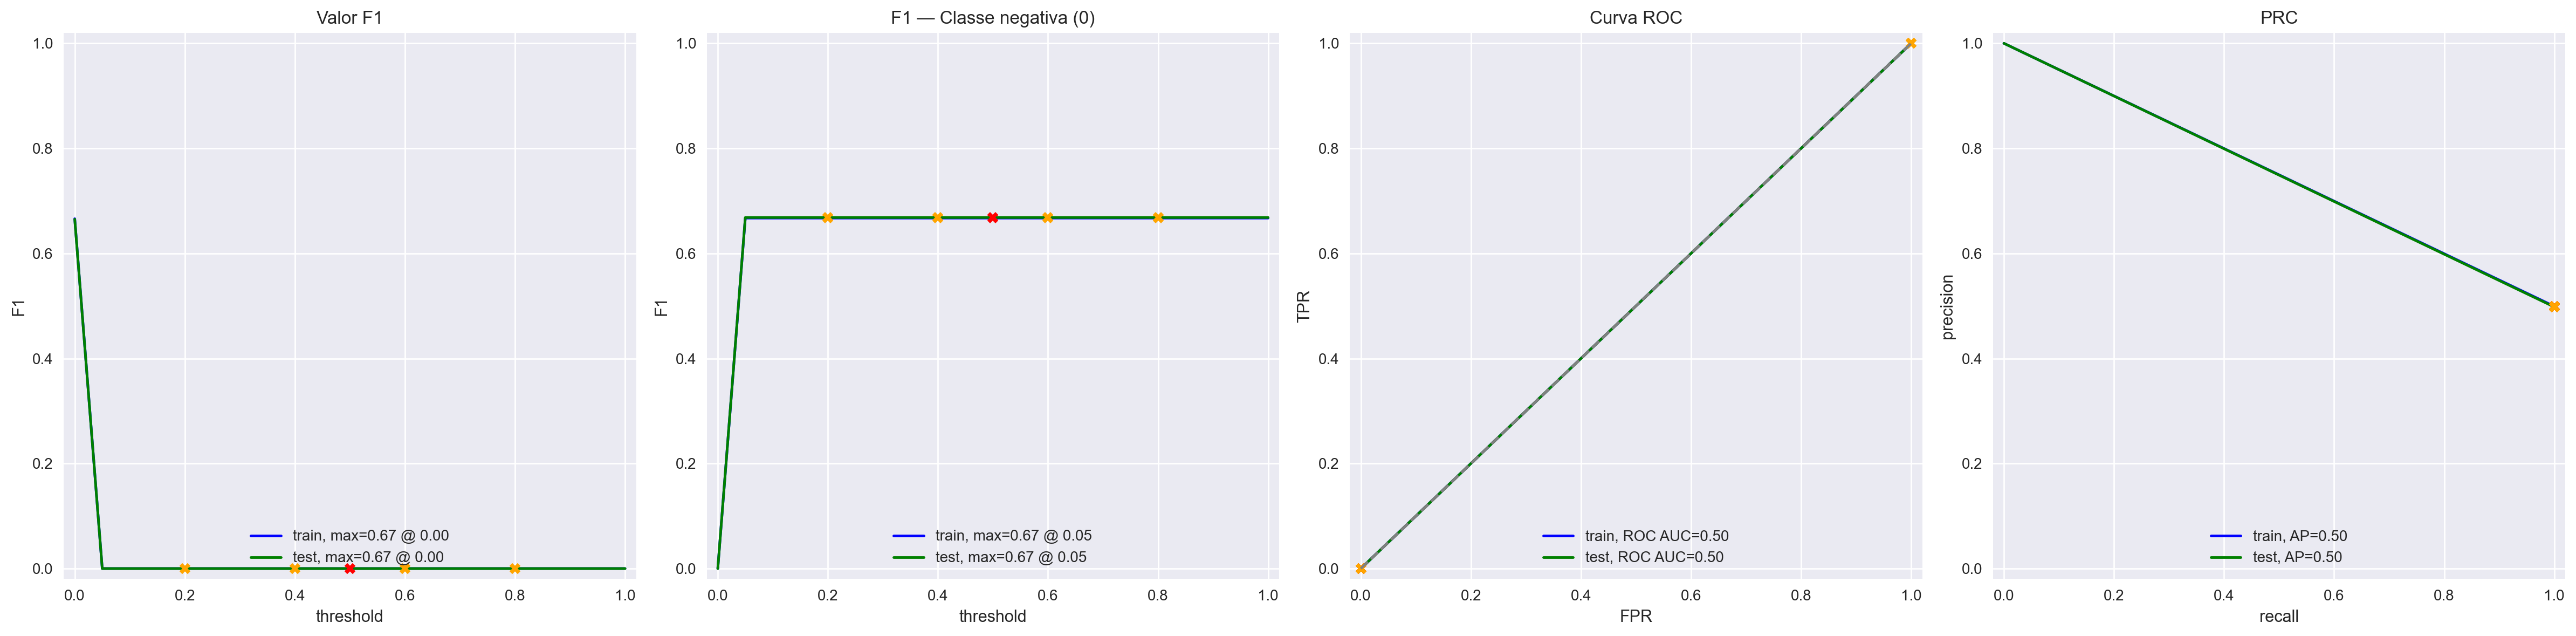

,Model,Process,Split,Accuracy,F1,F1 (negative),APS,ROC AUC
0,DummyClassifier,Baseline,test,0.5,0.0,0.67,0.5,0.5


In [120]:
dummy_results = evaluate_model_v2(
                                    model=dummy_model,
                                    train_features=dummy_train_features,
                                    train_target=train_target,
                                    test_features=dummy_test_features,
                                    test_target=test_target
                                )

# Adicionando os resultados do DummyClassifier ao DataFrame de resultados
df_results = pd.concat([df_results, pd.DataFrame({
    'Model': ['DummyClassifier'],
    'Process': ['Baseline'],
    'Split': ['test'],
    'Accuracy': [dummy_results.loc['Accuracy', 'test']],
    'F1': [dummy_results.loc['F1', 'test']],
    'F1 (negative)': [dummy_results.loc['F1 (negative)', 'test']],
    'APS': [dummy_results.loc['APS', 'test']],
    'ROC AUC': [dummy_results.loc['ROC AUC', 'test']]
})], ignore_index=True)

display(df_results)

### Modelo 1 - NLTK, TF-IDF e Regressão Logística

TF-IDF

In [121]:
import nltk

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from nltk.corpus import stopwords

In [122]:
# Pre processamento de texto: tokenização, remoção de stopwords e vetorização TF-IDF

nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

# Instanciando o vetor TF-IDF com remoção de stopwords
tfidf_vectorizer = TfidfVectorizer(stop_words=stop_words)

# Ajustando o vetor TF-IDF ao conjunto de treino e transformando os conjuntos de treino e teste
X1_train_tfidf = tfidf_vectorizer.fit_transform(text_train)
X1_test_tfidf = tfidf_vectorizer.transform(text_test)


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\pedro\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [123]:
# Instanciando o modelo de Regressão Logística com numero máximo de iterações definido para 1000 e uma semente aleatória para reprodutibilidade
model_1 = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)

# Treinando o modelo de Regressão Logística com os dados de treino vetorizados
model_1.fit(X1_train_tfidf, train_target)

LogisticRegression(max_iter=1000, random_state=12345)

               train  test
Accuracy        0.94  0.88
F1              0.94  0.88
F1 (negative)   0.94  0.88
APS             0.98  0.95
ROC AUC         0.98  0.95


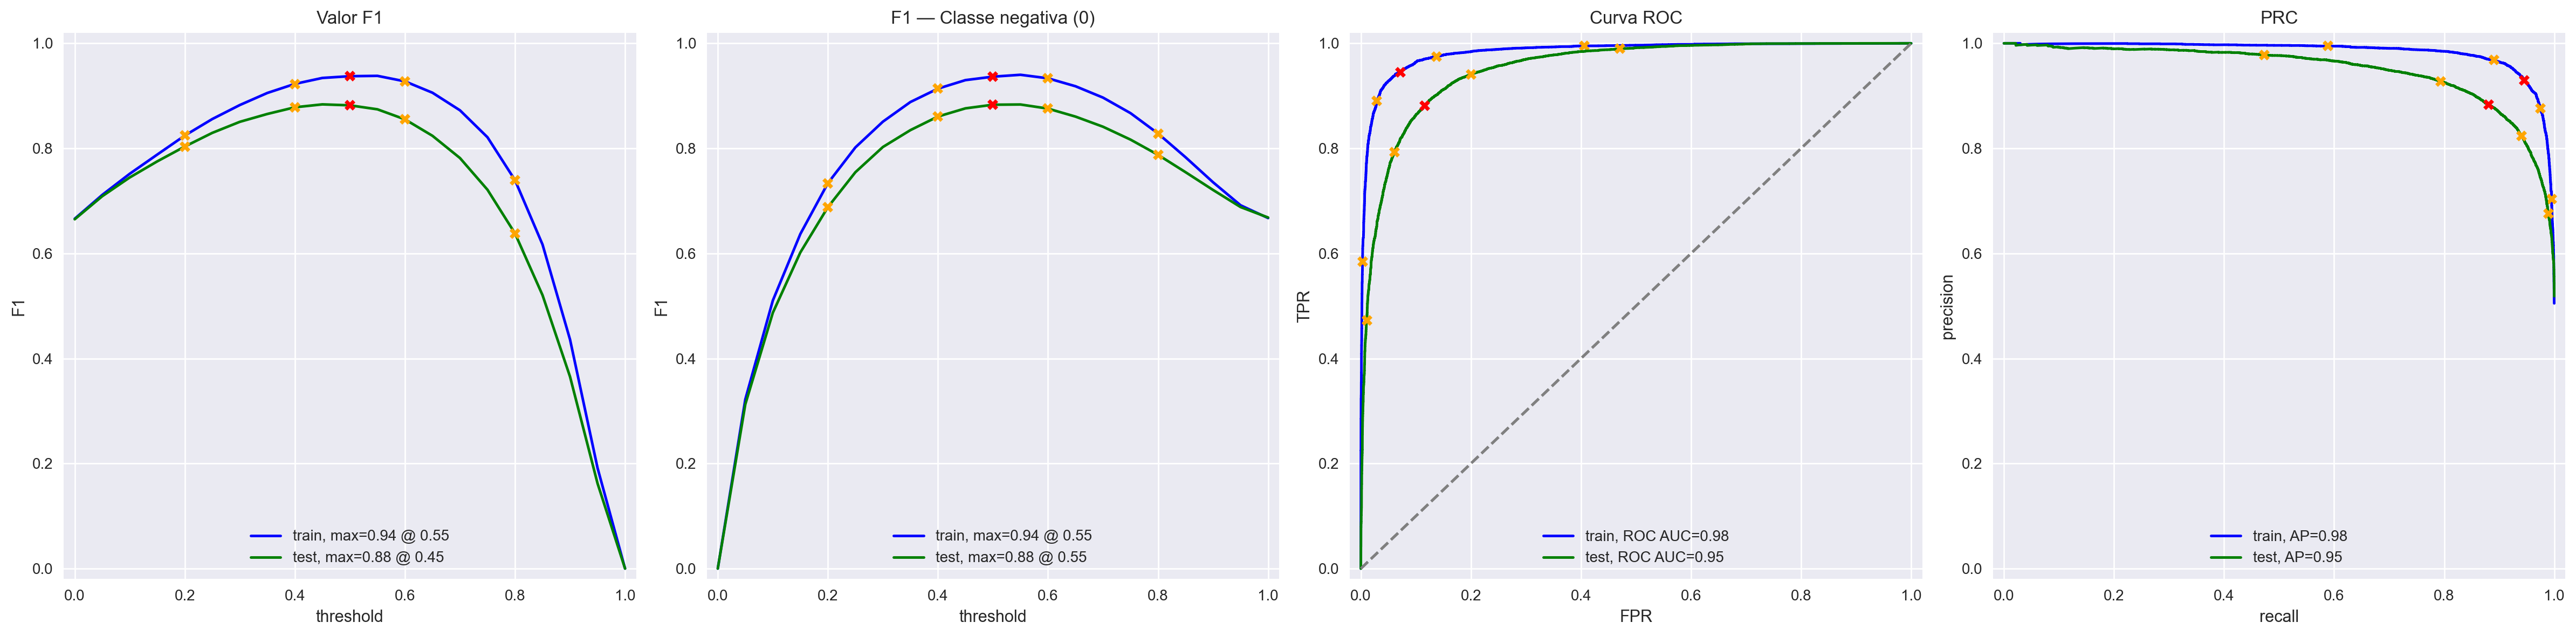

,Model,Process,Split,Accuracy,F1,F1 (negative),APS,ROC AUC
0,DummyClassifier,Baseline,test,0.50,0.00,0.67,0.50,0.50
1,LogisticRegression,TF-IDF + Stopwords Removal,test,0.88,0.88,0.88,0.95,0.95


In [124]:
# Avaliando o modelo de Regressão Logística com os dados de treino e teste vetorizados
model_1_results = evaluate_model_v2(model_1, X1_train_tfidf, train_target, X1_test_tfidf, test_target)

# Adicionando os resultados do modelo de Regressão Logística ao DataFrame de resultados
df_results = pd.concat([df_results, pd.DataFrame({
    'Model': ['LogisticRegression'],
    'Process': ['TF-IDF + Stopwords Removal'],
    'Split': ['test'],
    'Accuracy': [model_1_results.loc['Accuracy', 'test']],
    'F1': [model_1_results.loc['F1', 'test']],
    'F1 (negative)': [model_1_results.loc['F1 (negative)', 'test']],
    'APS': [model_1_results.loc['APS', 'test']],
    'ROC AUC': [model_1_results.loc['ROC AUC', 'test']]
})], ignore_index=True)

display(df_results)

### Modelo 2 - spaCy, TF-IDF e Regressão Logística

In [125]:
import spacy

nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

In [126]:
def text_preprocessing_2(text):
    
    doc = nlp(text)
    #tokens = [token.lemma_ for token in doc if not token.is_stop]
    tokens = [token.lemma_ for token in doc]
    
    return ' '.join(tokens)

In [128]:
# Pre-processamento e TF-IDF com lematização usando spaCy
X2_train = text_train.apply(text_preprocessing_2)
X2_test = text_test.apply(text_preprocessing_2)

# Vetorização TF-IDF sem stopwords
tfidf_vectorizer_no_sw = TfidfVectorizer()

X2_train_tfidf = tfidf_vectorizer_no_sw.fit_transform(X2_train)
X2_test_tfidf = tfidf_vectorizer_no_sw.transform(X2_test)

In [129]:
# Instanciando o modelo de Regressão Logística com numero máximo de iterações definido para 1000 e uma semente aleatória para reprodutibilidade
model_2 = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)

# Treinando o modelo de Regressão Logística com os dados de treino vetorizados
model_2.fit(X2_train_tfidf, train_target)

LogisticRegression(max_iter=1000, random_state=12345)

               train  test
Accuracy        0.93  0.88
F1              0.93  0.88
F1 (negative)   0.93  0.88
APS             0.98  0.95
ROC AUC         0.98  0.95


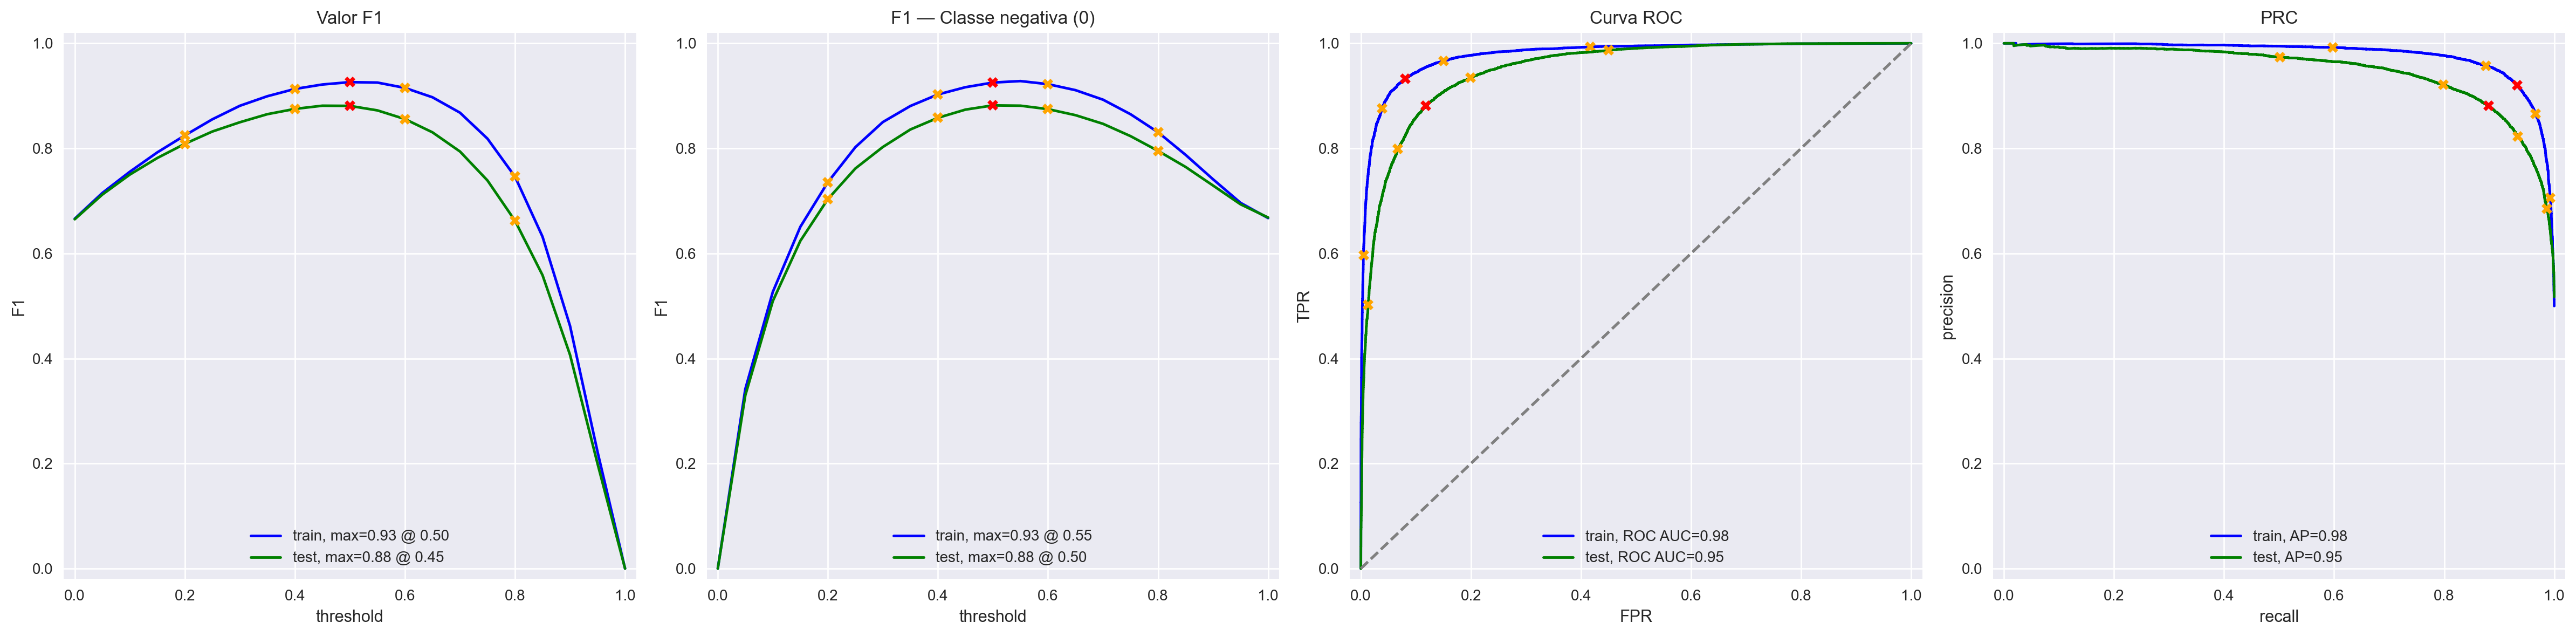

,Model,Process,Split,Accuracy,F1,F1 (negative),APS,ROC AUC
0,DummyClassifier,Baseline,test,0.50,0.00,0.67,0.50,0.50
1,LogisticRegression,TF-IDF + Stopwords Removal,test,0.88,0.88,0.88,0.95,0.95
2,Logistic Regression (Lemmatized),TF-IDF + Lemmatization,test,0.88,0.88,0.88,0.95,0.95


In [131]:
results_model_2 = evaluate_model_v2(model_2, X2_train_tfidf, train_target, X2_test_tfidf, test_target)

# Adicionando os resultados do modelo de Regressão Logística com lematização ao DataFrame de resultados
df_results = pd.concat([df_results, pd.DataFrame({
    'Model': ['Logistic Regression (Lemmatized)'],
    'Process': ['TF-IDF + Lemmatization'],
    'Split': ['test'],
    'Accuracy': [results_model_2.loc['Accuracy', 'test']],
    'F1': [results_model_2.loc['F1', 'test']],
    'F1 (negative)': [results_model_2.loc['F1 (negative)', 'test']],
    'APS': [results_model_2.loc['APS', 'test']],
    'ROC AUC': [results_model_2.loc['ROC AUC', 'test']]
})], ignore_index=True)
display(df_results)

### Modelo 3 - SpaCy, TF-IDF e LGBMClassifier

In [132]:
from lightgbm import LGBMClassifier

In [133]:
# Vamos aproveitar X2_train_tfidf e X2_test_tfidf do modelo anterior (com lematização) para treinar o modelo LightGBM
X3_train_tfidf = X2_train_tfidf
X3_test_tfidf = X2_test_tfidf

# Instanciando o modelo LightGBM com uma semente aleatória para reprodutibilidade
model_3 = LGBMClassifier(random_state=RANDOM_STATE)

# Treinando o modelo LightGBM com os dados de treino vetorizados
model_3.fit(X3_train_tfidf, train_target)

LGBMClassifier(random_state=12345)

               train  test
Accuracy        0.92  0.86
F1              0.92  0.86
F1 (negative)   0.92  0.86
APS             0.98  0.93
ROC AUC         0.98  0.94


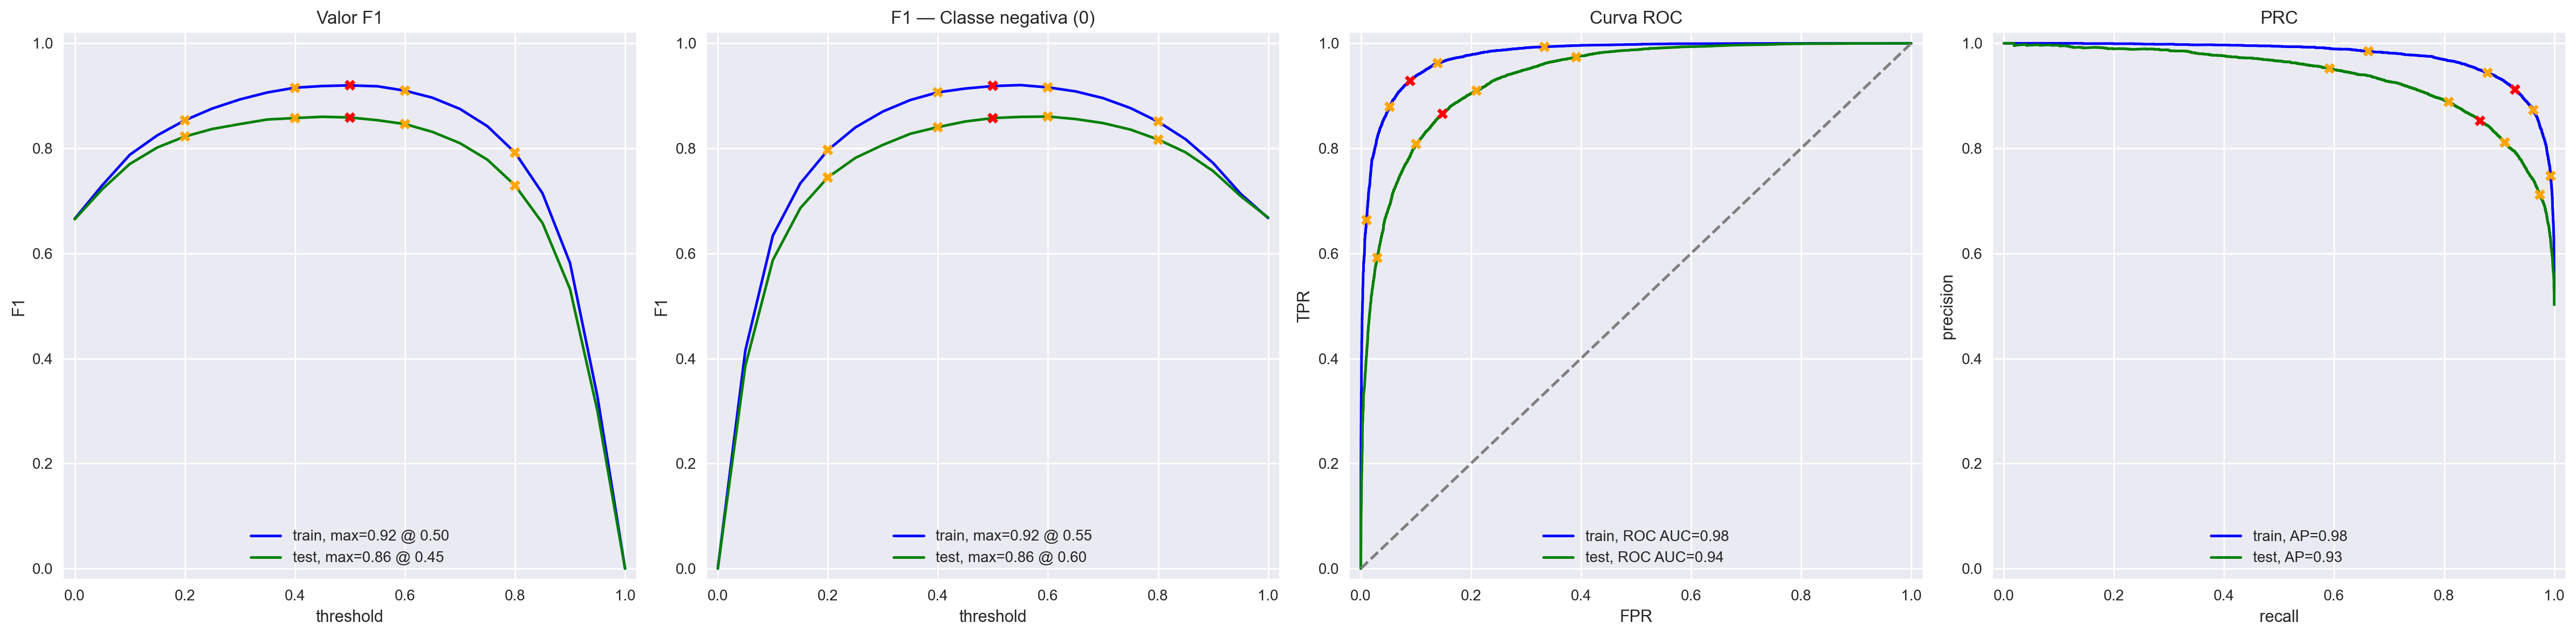

,Model,Process,Split,Accuracy,F1,F1 (negative),APS,ROC AUC
0,DummyClassifier,Baseline,test,0.50,0.00,0.67,0.50,0.50
1,LogisticRegression,TF-IDF + Stopwords Removal,test,0.88,0.88,0.88,0.95,0.95
2,Logistic Regression (Lemmatized),TF-IDF + Lemmatization,test,0.88,0.88,0.88,0.95,0.95
3,LightGBM,TF-IDF + Lemmatization,test,0.86,0.86,0.86,0.93,0.94


In [134]:
# Avaliando o modelo LightGBM com os dados de treino e teste vetorizados
results_model_3 = evaluate_model_v2(model_3, X3_train_tfidf, train_target, X3_test_tfidf, test_target)

# Adicionando os resultados do modelo LightGBM ao DataFrame de resultados
df_results = pd.concat([df_results, pd.DataFrame({
    'Model': ['LightGBM'],
    'Process': ['TF-IDF + Lemmatization'],
    'Split': ['test'],
    'Accuracy': [results_model_3.loc['Accuracy', 'test']],
    'F1': [results_model_3.loc['F1', 'test']],
    'F1 (negative)': [results_model_3.loc['F1 (negative)', 'test']],
    'APS': [results_model_3.loc['APS', 'test']],
    'ROC AUC': [results_model_3.loc['ROC AUC', 'test']]
})], ignore_index=True)

display(df_results)

###  Modelo 4 - BERT

In [135]:
import torch
import transformers

In [136]:
tokenizer = transformers.BertTokenizer.from_pretrained('bert-base-uncased')
config = transformers.BertConfig.from_pretrained('bert-base-uncased')
model = transformers.BertModel.from_pretrained('bert-base-uncased')

Downloading: 0.00B [00:00, ?B/s]

Downloading:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

Downloading: 0.00B [00:00, ?B/s]

Downloading:   0%|          | 0.00/570 [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/420M [00:00<?, ?B/s]

Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertModel: ['cls.predictions.transform.dense.weight', 'cls.predictions.bias', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight', 'cls.predictions.decoder.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


In [137]:
def BERT_text_to_embeddings(texts, max_length=512, batch_size=100, force_device=None, disable_progress_bar=False):
    
    ids_list = []
    attention_mask_list = []

    # texto para IDs de tokens preenchidos com suas máscaras de atenção
    
    for text in texts:
        encoded = tokenizer.encode_plus(
            text,
            add_special_tokens=True,
            max_length=max_length,
            padding='max_length',
            truncation=True,
            return_attention_mask=True
        )

        ids_list.append(encoded['input_ids'])
        attention_mask_list.append(encoded['attention_mask'])
    
    if force_device is not None:
        device = torch.device(force_device)
    else:
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        
    model.to(device)
    if not disable_progress_bar:
        print(f'Usando o dispositivo {device}.')
    
    # recebendo incorporações em lotes

    embeddings = []

    for i in tqdm(range(math.ceil(len(ids_list)/batch_size)), disable=disable_progress_bar):

        start = batch_size * i
        end = batch_size * (i + 1)
            
        ids_batch = torch.LongTensor(ids_list[start:end]).to(device)
        attention_mask_batch = torch.LongTensor(attention_mask_list[start:end]).to(device)
            
        with torch.no_grad():            
            model.eval()
            batch_embeddings = model(input_ids=ids_batch, attention_mask=attention_mask_batch)   
        embeddings.append(batch_embeddings[0][:,0,:].detach().cpu().numpy())
        
    return np.concatenate(embeddings)

In [139]:
# Atenção! A execução do BERT para milhares de textos pode levar muito tempo na CPU, pelo menos várias horas
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

if device.type == 'cpu':
    print("Aviso: O BERT é muito lento na CPU. Considere usar uma GPU para acelerar o processo.")
    print("Amostrando apenas 100 resenhas de treino para gerar embeddings do BERT.")
    text_sample_bert = text_train.sample(100, random_state=RANDOM_STATE)
    X4_train_bert = BERT_text_to_embeddings(text_sample_bert, batch_size=20)
else:
    print("Usando GPU para acelerar o processo do BERT.")
    X4_train_bert = BERT_text_to_embeddings(text_train, force_device='cuda')

Aviso: O BERT é muito lento na CPU. Considere usar uma GPU para acelerar o processo.
Amostrando apenas 100 resenhas de treino para gerar embeddings do BERT.
Usando o dispositivo cpu.


  0%|          | 0/5 [00:00<?, ?it/s]

In [141]:
if device.type == 'cpu':
    train_target_sample_bert = train_target.loc[text_sample_bert.index]
    print(text_sample_bert.shape)
    print(X4_train_bert.shape)
    print(train_target_sample_bert.shape)
else:
    print(text_train.shape)
    print(X4_train_bert.shape)
    print(train_target.shape)

(100,)
(100, 768)
(100,)


In [ ]:
# se você tiver as incorporações, é aconselhável salvá-las para tê-las prontas se 
# np.savez_compressed('features_9.npz', train_features_9=train_features_9, test_features_9=test_features_9)

# e carregar...
# with np.load('features_9.npz') as data:
#     train_features_9 = data['train_features_9']
#     test_features_9 = data['test_features_9']

## Minhas Resenhas

In [ ]:
# sinta-se à vontade para remover completamente essas resenhas e experimentar seus modelos nas suas próprias resenhas, as abaixo são apenas exemplos

my_reviews = pd.DataFrame([
    'Eu simplesmente não gostei, não é meu tipo de filme.',
    'Bem, eu fiquei entediado e dormi no meio do filme.',
    'Eu fiquei realmente fascinado com o filme',    
    'Os atores pareciam muito velhos e desinteressados, e mesmo assim foram pagos para participar do filme. Que roubo de dinheiro sem vergonha.',
    'Eu não esperava que a nova versão fosse tão boa! Os escritores realmente se importaram com o material original',
    'O filme tem seus prós e contras, mas eu sinto que em geral é um filme decente. Eu posso me imaginar indo assistir novamente.',
    'Que tentativa podre de comédia. Nem uma única piada cai, todo mundo age de forma irritante e barulhenta, nem crianças não vão gostar disso!',
    'Lançar na Netflix foi uma jogada corajosa e eu realmente aprecio ser capaz de assistir episódio após episódio, deste emocionante e inteligente novo drama.'
], columns=['review'])

my_reviews['review_norm'] = # <coloque aqui a mesma lógica de normalização do conjunto de dados principal>

my_reviews

### Modelo 2

In [740]:
texts = my_reviews['review_norm']

my_reviews_pred_prob = model_2.predict_proba(tfidf_vectorizer_2.transform(texts))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.14:  eu simplesmente não gostei, não é meu tipo de filme 
0.16:  bem, eu fiquei entediado e dormi no meio do filme 
0.54:  eu fiquei realmente fascinado com o filme
0.11:  os atores pareciam muito velhos e desinteressados, e mesmo assim foram pagos para participar do filme
0.31:  eu não esperava que a nova versão fosse tão boa, os escritores realmente se importaram com o material original
0.47:  o filme tem seus prós e contras, mas eu sinto que em geral é um filme decente, eu posso me
0.04:  que tentativa podre de comédia, nem uma única piada cai, todo mundo age de forma irritante e barulhenta, nem crian
0.82:  lançar na netflix foi uma jogada corajosa, eu realmente aprecio poder assistir episódio após epi


### Modelo 3

In [741]:
texts = my_reviews['review_norm']

my_reviews_pred_prob = model_3.predict_proba(tfidf_vectorizer_3.transform(texts.apply(lambda x: text_preprocessing_3(x))))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.40:  eu simplesmente não gostei, não é meu tipo de filme 
0.17:  bem, eu fiquei entediado e dormi no meio do filme 
0.51:  eu fiquei realmente fascinado com o filme
0.31:  os atores pareciam muito velhos e desinteressados, e mesmo assim foram pagos para participar do filme
0.31:  eu não esperava que a nova versão fosse tão boa, os escritores realmente se importaram com o material original
0.54:  o filme tem seus prós e contras, mas eu sinto que em geral é um filme decente, eu posso me
0.13:  que tentativa podre de comédia, nem uma única piada cai, todo mundo age de forma irritante e barulhenta, nem crian
0.86:  lançar na netflix foi uma jogada corajosa, eu realmente aprecio poder assistir episódio após epi


### Modelo 4

In [742]:
texts = my_reviews['review_norm']

tfidf_vectorizer_4 = tfidf_vectorizer_3
my_reviews_pred_prob = model_4.predict_proba(tfidf_vectorizer_4.transform(texts.apply(lambda x: text_preprocessing_3(x))))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.58:  eu simplesmente não gostei, não é meu tipo de filme 
0.32:  bem, eu fiquei entediado e dormi no meio do filme 
0.59:  eu fiquei realmente fascinado com o filme
0.43:  os atores pareciam muito velhos e desinteressados, e mesmo assim foram pagos para participar do filme
0.58:  eu não esperava que a nova versão fosse tão boa, os escritores realmente se importaram com o material original
0.63:  o filme tem seus prós e contras, mas eu sinto que em geral é um filme decente, eu posso me
0.27:  que tentativa podre de comédia, nem uma única piada cai, todo mundo age de forma irritante e barulhenta, nem crian
0.85:  lançar na netflix foi uma jogada corajosa, eu realmente aprecio poder assistir episódio após epi


### Modelo 9

In [743]:
texts = my_reviews['review_norm']

my_reviews_features_9 = BERT_text_to_embeddings(texts, disable_progress_bar=True)

my_reviews_pred_prob = model_9.predict_proba(my_reviews_features_9)[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.21:  eu simplesmente não gostei, não é meu tipo de filme 
0.01:  wbem, eu fiquei entediado e dormi no meio do filme 
0.99:  eu fiquei realmente fascinado com o filme
0.00:  os atores pareciam muito velhos e desinteressados, e mesmo assim foram pagos para participar do filme
0.21:  i didn t expect the reboot to be so good  writers really cared about the source material
0.94:  o filme tem seus prós e contras, mas eu sinto que em geral é um filme decente, eu posso me
0.09:  que tentativa podre de comédia, nem uma única piada cai, todo mundo age de forma irritante e barulhenta, nem crian
0.96:  lançar na netflix foi uma jogada corajosa, eu realmente aprecio poder assistir episódio após epi


## Conclusões

# Checklist

- [x]  O caderno foi aberto
- [ ]  Os dados de texto são carregados e pré-processados para vetorização
- [ ]  Os dados de texto são transformados em vetores
- [ ]  Os modelos são treinados e testados
- [ ]  O limiar da métrica foi atingido
- [ ]  Todas as células de código estão organizadas na ordem de sua execução
- [ ]  Todas as células de código podem ser executadas sem erros
- [ ]  Há conclusões 